# Quadriken und elliptische Kurven

Das Notebook geht von Gleichungen vom Grad 2 zu Gleichungen vom Grad 3 und von der Geometrie zur Kryptographie: die Klassifikation der Kegelschnitte und Quadrikflächen über Eigenwerte und Signatur, Kegelschnitte als Schnitte eines Kegels und als Keplerbahnen, quadratische Formen in Optimierung und Statistik, rationale Punkte auf Kegelschnitten (pythagoreische Tripel), die Gruppenaddition auf elliptischen Kurven, das Wachstum rationaler Punkte mit der Höhe für Kurven vom Grad 2, 3 und 4, elliptische Kurven über endlichen Körpern (Hasse-Schranke, Sato-Tate-Verteilung), der Schlüsselaustausch ECDH mit den klassischen Angriffen auf das diskrete Logarithmusproblem und Shors Algorithmus für dieses Problem als Simulation auf einer winzigen Kurve.

Warum sind Gleichungen vom Grad 2 vollständig verstanden, warum wird schon Grad 3 so reichhaltig, und wie wird aus der Gruppenstruktur einer kubischen Kurve ein Kryptosystem, das erst ein Quantencomputer bricht?

#### **Theorie**

**Begriffe.** Eine **Quadrik** ist die Nullstellenmenge eines Polynoms vom Grad 2 in $n$ Variablen, $x^\top Ax + b^\top x + c = 0$ mit symmetrischer Matrix $A$. In der Ebene heißen Quadriken **Kegelschnitte** (Ellipse, Parabel, Hyperbel), im Raum **Quadrikflächen** (Ellipsoid, Hyperboloide, Paraboloide, Kegel, Zylinder). **Entartet** heißt eine Quadrik, die in einfachere Stücke zerfällt, etwa in zwei Geraden oder einen Punkt.

**Klassifikation durch lineare Algebra.** Eine Drehung des Koordinatensystems macht $A$ diagonal (Spektralsatz), eine Verschiebung beseitigt die linearen Terme. Danach hängt der Typ nur noch von den Vorzeichen der Eigenwerte ab. Nach dem Trägheitssatz von Sylvester ist die **Signatur**, die Anzahl positiver und negativer Eigenwerte, von der Wahl der Koordinaten unabhängig.

**Projektive Sicht.** In homogenen Koordinaten $(x : y : z)$ wird jeder Kegelschnitt eine quadratische Form in drei Variablen mit einer $3\times3$-Matrix $\hat A$. Ellipse, Parabel und Hyperbel sind projektiv dieselbe Kurve; sie unterscheiden sich nur darin, ob die unendlich ferne Gerade sie in keinem, einem oder zwei Punkten trifft. Anschaulich sind es die Schnitte eines Kreiskegels mit verschieden stark geneigten Ebenen.

**Grad und Geschlecht.** Über $\mathbb C$ ist eine glatte ebene Kurve vom Grad $d$ eine geschlossene Fläche mit $g = (d-1)(d-2)/2$ Henkeln, dem **Geschlecht**. Das Geschlecht bestimmt, wie viele rationale Punkte eine Kurve haben kann:
- $g = 0$ (Kegelschnitte): keine oder unendlich viele, und dann alle durch eine rationale Parametrisierung bekannt;
- $g = 1$ (glatte Kubiken, **elliptische Kurven**): eine endlich erzeugte abelsche Gruppe;
- $g \ge 2$ (ab Grad 4): nur endlich viele (Satz von Faltings).

**Elliptische Kurven.** Eine elliptische Kurve ist eine glatte Kubik mit einem ausgezeichneten Punkt, in **Weierstraß-Form** $y^2 = x^3 + ax + b$ mit $4a^3 + 27b^2 \ne 0$ und dem Punkt $\mathcal O$ im Unendlichen. Ihre Punkte bilden eine abelsche Gruppe: Drei Punkte auf einer Geraden ergeben null. Über $\mathbb C$ ist die Kurve ein Torus $\mathbb C/\Lambda$, über $\mathbb Q$ ist die Gruppe endlich erzeugt, $\mathbb Z^r \oplus T$ (Mordell-Weil), über einem endlichen Körper $\mathbb F_p$ ist sie endlich mit etwa $p$ Elementen. Der Name kommt von den elliptischen Integralen, nicht von Ellipsen.

**Kryptographie und Quantencomputer.** In der Gruppe $E(\mathbb F_p)$ ist $kP$ aus $k$ schnell berechnet, aber $k$ aus $kP$ zu bestimmen, der **diskrete Logarithmus**, kostet klassisch etwa $\sqrt N$ Schritte. Darauf beruhen Schlüsselaustausch (ECDH) und Signaturen (ECDSA, Ed25519) in TLS, SSH, Signal und Bitcoin. Shors Algorithmus löst das Problem in Polynomialzeit: Die Quanten-Fourier-Transformation macht die verborgene Periodenstruktur der Funktion $(a, b) \mapsto aP + bQ$ sichtbar.

#### **Herleitung**

**1. Hauptachsentransformation.** Für $F(x) = x^\top Ax + b^\top x + c$ mit invertierbarem $A$ verschiebt $x = x_0 + y$ mit $x_0 = -\tfrac12A^{-1}b$ den Ursprung ins **Zentrum**. Die linearen Terme verschwinden, und es bleibt $y^\top Ay + c'$ mit $c' = c + \tfrac12 b^\top x_0$. Mit der erweiterten Matrix
$$\hat A = \begin{pmatrix} A & b/2 \\ b^\top/2 & c\end{pmatrix}$$
ist $\det\hat A = \det A\,(c - \tfrac14 b^\top A^{-1}b)$ (Schur-Komplement), also $c' = \det\hat A/\det A$. Eine Drehung $y = Ru$, deren Spalten die Eigenvektoren von $A$ sind, gibt die **Normalform** $\lambda_1u_1^2 + \dots + \lambda_nu_n^2 + c' = 0$. Die Eigenvektoren sind die Hauptachsen, die Halbachsen sind $\sqrt{-c'/\lambda_i}$, soweit reell.

**2. Klassifikation der Kegelschnitte.** Für $ax^2 + bxy + cy^2 + dx + ey + f = 0$ genügen zwei Invarianten, $\delta = \det A$ und $\Delta = \det\hat A$; Drehungen und Verschiebungen ändern sie nicht. Ist $\Delta \ne 0$, ist der Kegelschnitt nicht entartet:
- $\delta > 0$: Ellipse (mit reellen Punkten nur, wenn $\operatorname{tr}A\cdot\Delta < 0$, also wenn $c'$ das entgegengesetzte Vorzeichen der Eigenwerte hat);
- $\delta < 0$: Hyperbel;
- $\delta = 0$: Parabel.

Ist $\Delta = 0$, zerfällt er in zwei sich schneidende Geraden ($\delta < 0$), einen Punkt ($\delta > 0$) oder zwei parallele Geraden ($\delta = 0$). Bei der Parabel ist ein Eigenwert null und es gibt kein Zentrum. Den Scheitel findet man, indem man in der gedrehten Gleichung $\lambda_2u_2^2 + d_1'u_1 + d_2'u_2 + f = 0$ das Quadrat in $u_2$ ergänzt; die Normalform ist $\lambda_2w_2^2 + d_1'w_1 = 0$.

**3. Kegelschnitte als Schnitte und als Bahnen.** Die Ebene $z = 1 + mx$ schneidet den Kegel $x^2 + y^2 = z^2$. Auf dem oberen Kegel ist $z = r = \sqrt{x^2+y^2}$, also $r = 1 + mr\cos\varphi$ und
$$r(\varphi) = \frac{1}{1 - m\cos\varphi}.$$
Das ist die Brennpunktgleichung eines Kegelschnitts mit einem Brennpunkt im Ursprung und der **Exzentrizität** $e = m$: Ellipse für $m < 1$, Parabel für $m = 1$ (die Ebene ist parallel zu einer Mantellinie), Hyperbel für $m > 1$. Dieselbe Gleichung beschreibt die Keplerbahnen. Im Potential $-\mu/r$ ist neben Energie $E$ und Drehimpuls $L$ auch der **Laplace-Runge-Lenz-Vektor** $\mathbf A = \mathbf v \times \mathbf L - \mu\,\hat{\mathbf r}$ erhalten. Es ist $\mathbf A\cdot\mathbf r = \mathbf L\cdot(\mathbf r \times \mathbf v) - \mu r = L^2 - \mu r$ und zugleich $\mathbf A\cdot\mathbf r = |\mathbf A|\,r\cos\theta$. Daraus folgt
$$r = \frac{L^2/\mu}{1 + e\cos\theta}, \qquad e = \frac{|\mathbf A|}{\mu} = \sqrt{1 + \frac{2EL^2}{\mu^2}} .$$
Startet ein Körper bei $r = 1$ senkrecht zum Radius mit der Geschwindigkeit $v_0$ (und $\mu = 1$), ist $L = v_0$, $E = v_0^2/2 - 1$ und $e = |v_0^2 - 1|$.

**4. Quadrikflächen und Regelflächen.** Nach Verschiebung, Drehung und Skalierung bleiben im Raum $x^2 + y^2 + z^2 = 1$ (Ellipsoid), $x^2 + y^2 - z^2 = 1$ (einschaliges Hyperboloid), $x^2 + y^2 - z^2 = -1$ (zweischaliges Hyperboloid), $x^2 + y^2 = z^2$ (Kegel), $z = x^2 + y^2$ (elliptisches Paraboloid), $z = x^2 - y^2$ (hyperbolisches Paraboloid) und die Zylinder. Projektiv entscheidet allein die Signatur der $4\times4$-Matrix $\hat A$: Ellipsoid, zweischaliges Hyperboloid und elliptisches Paraboloid haben die Signatur $(3, 1)$ und sind projektiv eine Kugel; einschaliges Hyperboloid und hyperbolisches Paraboloid haben $(2, 2)$. Die Quadriken vom Typ $(2, 2)$ sind **doppelt geregelt**: Durch jeden Punkt gehen zwei Geraden, die ganz auf der Fläche liegen. Beim Hyperboloid sieht man das an der Zerlegung
$$(x - z)(x + z) = (1 - y)(1 + y),$$
explizit liegen die Geraden $t \mapsto (\cos\varphi - t\sin\varphi,\ \sin\varphi + t\cos\varphi,\ \pm t)$ auf der Fläche, denn $(\cos\varphi - t\sin\varphi)^2 + (\sin\varphi + t\cos\varphi)^2 - t^2 = 1$. Beim Sattel $z = x^2 - y^2 = (x - y)(x + y)$ sind es die Geraden, auf denen $x - y$ oder $x + y$ konstant ist. Deshalb kann man Kühltürme aus geraden Stäben bauen.

**5. Quadratische Formen in Optimierung und Statistik.** Nahe einem Minimum ist jede glatte Funktion $f(x) \approx f(x^*) + \tfrac12(x - x^*)^\top H(x - x^*)$ mit der Hesse-Matrix $H$; ihre Niveaumengen sind Ellipsoide mit den Eigenvektoren von $H$ als Achsen. Für $f(x) = \tfrac12 x^\top Hx$ ist das Gradientenverfahren $x_{k+1} = (I - \alpha H)x_k$: Die Komponente längs des Eigenvektors zu $\lambda_i$ schrumpft pro Schritt um den Faktor $|1 - \alpha\lambda_i|$. Die beste feste Schrittweite $\alpha = 2/(\lambda_{\min} + \lambda_{\max})$ macht die beiden äußeren Faktoren gleich, und der Fehler fällt wie
$$\left(\frac{\kappa - 1}{\kappa + 1}\right)^k, \qquad \kappa = \frac{\lambda_{\max}}{\lambda_{\min}} \ \text{(Konditionszahl)}.$$
Langgestreckte Ellipsen bedeuten also langsame Konvergenz. Das Newton-Verfahren $x_{k+1} = x_k - H^{-1}\nabla f(x_k)$ ist bei einer quadratischen Funktion nach einem Schritt am Ziel. In der Statistik hat die Normalverteilung die Dichte $\propto e^{-d^2/2}$ mit der **Mahalanobis-Distanz** $d^2 = (x - \mu)^\top\Sigma^{-1}(x - \mu)$. $d^2$ ist $\chi^2$-verteilt mit $n$ Freiheitsgraden; in zwei Dimensionen liegt der Anteil $1 - e^{-r^2/2}$ der Stichprobe in der Ellipse $d \le r$.

**6. Rationale Parametrisierung.** Die Gerade $y = t(x + 1)$ durch $(-1, 0)$ schneidet den Einheitskreis in $(1 + t^2)x^2 + 2t^2x + t^2 - 1 = 0$. Eine Nullstelle ist $x = -1$; nach Vieta ist das Produkt der Nullstellen $(t^2 - 1)/(1 + t^2)$, also ist die zweite
$$x = \frac{1 - t^2}{1 + t^2}, \qquad y = \frac{2t}{1 + t^2}.$$
Rationale $t$ geben rationale Punkte und umgekehrt, denn die Steigung zwischen zwei rationalen Punkten ist rational. Mit $t = m/n$ entsteht das Tripel $(n^2 - m^2,\ 2mn,\ n^2 + m^2)$; es ist primitiv genau dann, wenn $\gcd(m, n) = 1$ und $m \not\equiv n \pmod 2$. Die Paare $(m, n)$ mit $m < n$ und $m^2 + n^2 \le C$ füllen einen Achtelkreis der Fläche $\pi C/8$, davon ist der Anteil $6/\pi^2$ teilerfremd und davon wieder $2/3$ von verschiedener Parität: Es gibt etwa $C/(2\pi)$ primitive Tripel mit Hypotenuse $\le C$.

Dasselbe Argument parametrisiert jeden Kegelschnitt, sobald man einen rationalen Punkt hat. Ob es einen gibt, ist eine eigene Frage. $x^2 + y^2 = 3$ hat keinen: Aus $X^2 + Y^2 = 3Z^2$ ohne gemeinsamen Teiler folgt modulo 3 (Quadrate sind dort 0 oder 1), dass $3 \mid X$ und $3 \mid Y$, dann $9 \mid 3Z^2$, also $3 \mid Z$. Allgemein hat ein Kegelschnitt genau dann einen rationalen Punkt, wenn er reelle Punkte und $p$-adische Punkte für jede Primzahl $p$ hat (Satz von Hasse-Minkowski, ein Lokal-Global-Prinzip). Für $x^2 + y^2 = n$ heißt das: Jede Primzahl $q \equiv 3 \pmod 4$ teilt $n$ in gerader Potenz.

**7. Die Gruppenaddition.** Die Gerade $y = \lambda x + \nu$ durch $P_1 = (x_1, y_1)$ und $P_2 = (x_2, y_2)$, eingesetzt in $y^2 = x^3 + ax + b$, gibt
$$x^3 - \lambda^2x^2 + (a - 2\lambda\nu)x + (b - \nu^2) = 0 .$$
Zwei Nullstellen sind $x_1$ und $x_2$. Nach Vieta ist die Summe aller drei $\lambda^2$, also liegt der dritte Schnittpunkt bei $x_3 = \lambda^2 - x_1 - x_2$, und $P_1 + P_2$ ist sein Spiegelbild an der $x$-Achse:
$$x_3 = \lambda^2 - x_1 - x_2, \qquad y_3 = \lambda(x_1 - x_3) - y_1, \qquad \lambda = \frac{y_2 - y_1}{x_2 - x_1} \ \text{ bzw. } \ \lambda = \frac{3x_1^2 + a}{2y_1}\ \text{ für } P_1 = P_2 .$$
Die Regel „drei Punkte auf einer Geraden ergeben null" mit $\mathcal O$ als neutralem Element und $-(x, y) = (x, -y)$ ist offensichtlich kommutativ. Die Assoziativität ist der schwierige Teil: Sie folgt aus dem Satz von Cayley-Bacharach über Kubiken durch acht Punkte, oder über $\mathbb C$ aus dem Isomorphismus mit dem Torus $\mathbb C/\Lambda$ über die Weierstraßsche $\wp$-Funktion, unter dem die Addition einfach die Addition komplexer Zahlen ist. Die Formeln enthalten nur Körperoperationen; das Gruppengesetz gilt deshalb über jedem Körper, über $\mathbb Q$ ebenso wie über $\mathbb F_p$. Über $\mathbb R$ hat die Kurve eine Komponente, wenn $x^3 + ax + b$ eine reelle Nullstelle hat, und zwei (ein „Ei" und einen unbeschränkten Ast), wenn es drei sind, also wenn $4a^3 + 27b^2 < 0$. Der unbeschränkte Ast ist eine Untergruppe; die Summe zweier Punkte auf dem Ei liegt auf ihm.

**8. Höhen und das Wachstum rationaler Punkte.** Die **Höhe** misst die arithmetische Komplexität eines rationalen Punkts: $H(x) = \max(|p|, |q|)$ für $x = p/q$ in gekürzter Form, $h = \log H$. Auf dem Kreis (Geschlecht 0) gibt es etwa $8\cdot C/(2\pi) = 4C/\pi$ Punkte mit Nenner $\le C$ (acht pro primitivem Tripel, Herleitung 6): Die Anzahl wächst linear. Auf einer elliptischen Kurve ist $x(2P)$ eine rationale Funktion vom Grad 4 in $x(P)$; jede Verdopplung vervierfacht ungefähr die Höhe, und allgemein ist
$$h(x(nP)) = \hat h_x(P)\,n^2 + O(1).$$
Der Grenzwert $\hat h_x(P) = \lim h(x(nP))/n^2$ ist die **kanonische Höhe** (in der Normierung von Silverman ist $\hat h = \hat h_x/2$). Bei Rang $r$ gibt es deshalb nur etwa $c\,(\log C)^{r/2}$ Punkte mit Höhe $\le C$, bei Rang 1 also $\sim\sqrt{\log C}$. Ab Geschlecht 2 bleibt die Anzahl beschränkt (Faltings). Für die Fermat-Quartik $x^4 + y^4 = 1$ zeigte schon Fermat mit unendlichem Abstieg, dass es nur die vier trivialen Punkte gibt.

**9. Elliptische Kurven über endlichen Körpern.** Zu jedem $x \in \mathbb F_p$ gibt es zwei, einen oder keinen Punkt, je nachdem, ob $x^3 + ax + b$ ein Quadrat ungleich null, null oder kein Quadrat ist. Mit dem Legendre-Symbol $\chi$ ist deshalb
$$\#E(\mathbb F_p) = p + 1 + \sum_{x\in\mathbb F_p}\chi(x^3 + ax + b) = p + 1 - a_p .$$
Die Summe verhält sich wie eine Irrfahrt aus $p$ Schritten $\pm1$, und tatsächlich gilt die **Hasse-Schranke** $|a_p| \le 2\sqrt p$ (Hasse 1933; sie ist die Riemannsche Vermutung für Kurven über endlichen Körpern). Schreibt man $a_p = 2\sqrt p\cos\theta_p$, sind die Winkel bei Kurven ohne komplexe Multiplikation nach der **Sato-Tate-Verteilung** mit Dichte $\tfrac2\pi\sin^2\theta$ verteilt (bewiesen 2008 bis 2011 von Taylor und Mitarbeitern). Dann hat $x = a_p/2\sqrt p$ die Halbkreisdichte $\tfrac2\pi\sqrt{1 - x^2}$ mit $\langle x^2\rangle = 1/4$ und $\langle x^4\rangle = 1/8$. Kurven mit komplexer Multiplikation verhalten sich anders: Für $y^2 = x^3 - x$ und $p \equiv 3 \pmod 4$ ist $\chi(-1) = -1$, also $\chi(f(-x)) = -\chi(f(x))$; die Summe hebt sich paarweise weg, und $a_p = 0$. Die Gruppe $E(\mathbb F_p)$ ist zyklisch oder ein Produkt $\mathbb Z_{n_1} \times \mathbb Z_{n_2}$ mit $n_1 \mid n_2$.

**10. Das diskrete Logarithmusproblem.** In einer zyklischen Gruppe der Ordnung $N$ mit Erzeuger $G$ ist $kG$ mit **Double-and-Add** in höchstens $2\log_2 k$ Gruppenoperationen berechnet: $k$ binär schreiben, für jedes Bit verdoppeln, für jede Eins addieren. Umgekehrt $k$ aus $Q = kG$ zu bestimmen, gelingt generisch nur mit etwa $\sqrt N$ Operationen:
- **Baby-Step-Giant-Step:** Mit $m = \lceil\sqrt N\rceil$ ist $k = im + j$. Man speichert die $m$ „Baby Steps" $jG$ und sucht unter den „Giant Steps" $Q - imG$ einen Treffer: höchstens $2m$ Operationen und $m$ Speicherplätze.
- **Pollard-Rho:** Eine pseudozufällige Folge $X_{i+1} = X_i + M_{j(X_i)}$ mit festen $M_j = c_jG + d_jQ$ kennt für jedes Glied die Darstellung $X_i = \alpha_iG + \beta_iQ$. Nach etwa $\sqrt{\pi N/2}$ Schritten wiederholt sich ein Punkt (Geburtstagsparadoxon), Floyds Zyklensuche findet das ohne Speicher, und aus $\alpha_iG + \beta_iQ = \alpha_jG + \beta_jQ$ folgt $k = (\alpha_j - \alpha_i)(\beta_i - \beta_j)^{-1} \bmod N$.
- **Pohlig-Hellman:** Ist $N$ zusammengesetzt, zerfällt das Problem in Probleme in den Untergruppen von Primzahlordnung. Kryptographische Kurven haben deshalb (fast) Primzahlordnung, und nicht $N = p$ (anomale Kurven sind über $p$-adische Logarithmen in Polynomialzeit angreifbar).

Für elliptische Kurven ist kein besserer allgemeiner Angriff bekannt, anders als in $\mathbb F_p^\times$, wo der Index-Calculus subexponentiell ist. Eine Kurve mit $N \approx 2^{256}$ bietet deshalb etwa 128 Bit Sicherheit; mit RSA braucht man dafür etwa 3072 Bit. Beim **Schlüsselaustausch ECDH** veröffentlichen Alice $A = aG$ und Bob $B = bG$; beide berechnen $aB = bA = abG$, ein Lauscher müsste dafür einen diskreten Logarithmus lösen.

**11. Shors Algorithmus für den diskreten Logarithmus.** Sei $Q = kP$ in einer Gruppe von Primzahlordnung $N$. Die Funktion $f(a, b) = aP + bQ = (a + kb)P$ auf $\mathbb Z_N^2$ ist konstant auf den Nebenklassen der **verborgenen Untergruppe** $H = \{(a, b) : a + kb \equiv 0\} = \langle(-k, 1)\rangle$. Der Algorithmus:
1. Zwei Register in gleichmäßige Überlagerung bringen und $f$ reversibel in ein drittes rechnen: $\frac1N\sum_{a,b}|a\rangle|b\rangle|aP + bQ\rangle$.
2. Das dritte Register messen (oder ignorieren). Ergibt die Messung $cP$, bleibt die Nebenklasse $\frac1{\sqrt N}\sum_b|c - kb\rangle|b\rangle$.
3. Auf beide Register die QFT $|x\rangle \mapsto \frac{1}{\sqrt N}\sum_y\omega^{xy}|y\rangle$ mit $\omega = e^{2\pi i/N}$ anwenden. Die Amplitude von $|u, v\rangle$ ist
$$\frac{1}{N^{3/2}}\,\omega^{uc}\sum_b\omega^{b(v - ku)},$$
also null außer für $v \equiv ku$. Gemessen wird ein zufälliges Element der dualen Gruppe $H^\perp = \{(u, ku)\}$, unabhängig von $c$.
4. Klassische Nachbearbeitung: Ist $u \ne 0$, ist $k = vu^{-1} \bmod N$. Erfolgswahrscheinlichkeit $1 - 1/N$ pro Durchlauf.

Die QFT macht aus der Verschiebung $c$ der Nebenklasse eine Phase $\omega^{uc}$, die bei der Messung herausfällt, und sammelt die Amplitude auf $H^\perp$. Ein echter Quantenrechner hat Register mit $Q = 2^n$ statt $N$ Zuständen; dann liegen die Spitzen nur ungefähr bei $(u, v) \approx (jQ/N,\ (jk \bmod N)\,Q/N)$, und man rundet. Die QFT auf $n$ Qubits braucht $n$ Hadamard-Gatter, $n(n-1)/2$ kontrollierte Phasengatter $R_k = \operatorname{diag}(1, e^{2\pi i/2^k})$ und $\lfloor n/2\rfloor$ Vertauschungen, mit der halbklassischen Variante (Griffiths-Niu) sogar nur ein einziges, immer wieder gemessenes Steuerqubit. Fast der ganze Aufwand steckt in Schritt 1, der reversiblen Punktaddition mit modularer Inversion: Roetteler et al. (2017) schätzen für eine 256-Bit-Kurve $9n + 2\lceil\log_2 n\rceil + 10 = 2330$ logische Qubits und etwa $1.3\cdot10^{11}$ Toffoli-Gatter, deutlich weniger als für RSA-3072.

#### **Code**

Gemeinsame Werkzeuge: Kegelschnitte (Invarianten, Hauptachsen, Exzentrizität) und elliptische Kurven (Gruppenaddition über $\mathbb Q$, $\mathbb R$ und $\mathbb F_p$, Double-and-Add, Punkte zählen).

In [1]:
# Alles hier (numpy, scipy, sympy, matplotlib) ist in Colab vorinstalliert
import random
import time
from fractions import Fraction
from math import gcd, isqrt, log, ceil
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------- Kegelschnitte  a x² + b xy + c y² + d x + e y + f = 0 ----------
def conic_matrices(coef):
    a, b, c, d, e, f = coef
    A = np.array([[a, b / 2], [b / 2, c]], dtype=float)
    Ahat = np.array([[a, b / 2, d / 2], [b / 2, c, e / 2], [d / 2, e / 2, f]], dtype=float)
    return A, Ahat

def conic_value(coef, x, y):
    a, b, c, d, e, f = coef
    return a * x * x + b * x * y + c * y * y + d * x + e * y + f

def classify_conic(coef, tol=1e-9):
    """Typ aus den Invarianten δ = det A und Δ = det Â (Herleitung 2), skaleninvariant gemacht."""
    A, Ahat = conic_matrices(coef)
    s = np.max(np.abs(Ahat))
    delta, Delta = np.linalg.det(A / s), np.linalg.det(Ahat / s)
    if abs(Delta) < tol:
        return "Geradenpaar" if delta < -tol else ("Punkt" if delta > tol else "parallele Geraden")
    if delta > tol:
        return "Ellipse" if np.trace(A) * Delta < 0 else "leere Ellipse"
    return "Hyperbel" if delta < -tol else "Parabel"

def principal_axes(coef, tol=1e-12):
    """Hauptachsentransformation (Herleitung 1 und 2): Eigenwerte, Drehung R, Zentrum oder Scheitel x0 und
    die Normalform als Funktion der Koordinaten w = Rᵀ(x − x0)."""
    a, b, c, d, e, f = coef
    A, Ahat = conic_matrices(coef)
    lam, R = np.linalg.eigh(A)
    bvec = np.array([d, e], dtype=float)
    if abs(np.linalg.det(A)) > tol:                         # Mittelpunktskegelschnitt
        x0 = -0.5 * np.linalg.solve(A, bvec)
        const = np.linalg.det(Ahat) / np.linalg.det(A)      # c' = Δ/δ
        return dict(lam=lam, R=R, x0=x0, const=const,
                    normal=lambda w: lam[0] * w[0] ** 2 + lam[1] * w[1] ** 2 + const)
    i, j = np.argsort(np.abs(lam))                          # λ_i = 0 (Achsenrichtung), λ_j ≠ 0
    bp = R.T @ bvec                                         # lineare Koeffizienten im gedrehten System
    u = np.zeros(2)
    u[j] = -bp[j] / (2 * lam[j])                            # quadratische Ergänzung in u_j
    u[i] = -(f - bp[j] ** 2 / (4 * lam[j])) / bp[i]
    return dict(lam=lam, R=R, x0=R @ u, const=0.0, lin=bp[i], i=i, j=j,
                normal=lambda w: lam[j] * w[j] ** 2 + bp[i] * w[i])

def conic_eccentricity(coef):
    """Exzentrizität aus der Normalform λ₁u² + λ₂v² = k mit k = −Δ/δ: e² = 1 − λ₁/λ₂, wobei λ₁ der
    betragskleinste Eigenwert mit dem Vorzeichen von k ist (große Halbachse bzw. reelle Achse)."""
    A, Ahat = conic_matrices(coef)
    lam = np.linalg.eigvalsh(A)
    k = -np.linalg.det(Ahat) / np.linalg.det(A)
    idx = [i for i in range(2) if np.sign(lam[i]) == np.sign(k)]
    i1 = min(idx, key=lambda i: abs(lam[i]))
    return np.sqrt(max(0.0, 1 - lam[i1] / lam[1 - i1]))

# ---------- Elliptische Kurven  y² = x³ + a x + b ----------
O = None                                                    # der Punkt im Unendlichen, das neutrale Element

def ec_add(P, Q, a, p=None):
    """P + Q mit der Sekanten-Tangenten-Regel (Herleitung 7).
    p = None: über ℚ (Fraction) oder ℝ (float); sonst über dem Körper 𝔽ₚ."""
    if P is O:
        return Q
    if Q is O:
        return P
    (x1, y1), (x2, y2) = P, Q
    if p is None:
        if x1 == x2 and y1 == -y2:
            return O
        lam = (3 * x1 * x1 + a) / (2 * y1) if x1 == x2 else (y2 - y1) / (x2 - x1)
        x3 = lam * lam - x1 - x2
        return (x3, lam * (x1 - x3) - y1)
    if x1 == x2 and (y1 + y2) % p == 0:
        return O
    if x1 == x2:
        lam = (3 * x1 * x1 + a) * pow(2 * y1, -1, p) % p
    else:
        lam = (y2 - y1) * pow(x2 - x1, -1, p) % p
    x3 = (lam * lam - x1 - x2) % p
    return (x3, (lam * (x1 - x3) - y1) % p)

def ec_neg(P, p=None):
    if P is O:
        return O
    return (P[0], -P[1] % p) if p else (P[0], -P[1])

def ec_mul(k, P, a, p=None):
    """k·P mit Double-and-Add: O(log k) Gruppenoperationen (Herleitung 10)."""
    if k < 0:
        return ec_mul(-k, ec_neg(P, p), a, p)
    R = O
    while k:
        if k & 1:
            R = ec_add(R, P, a, p)
        P = ec_add(P, P, a, p)
        k >>= 1
    return R

def ec_points(a, b, p):
    """Alle Punkte von y² = x³ + ax + b über 𝔽ₚ, beginnend mit O (für kleine p)."""
    roots = {}
    for y in range(p):
        roots.setdefault(y * y % p, []).append(y)
    return [O] + [(x, y) for x in range(p) for y in roots.get((x ** 3 + a * x + b) % p, [])]

def ec_count(a, b, p):
    """#E(𝔽ₚ) = p + 1 + Σ_x χ(x³ + ax + b) mit dem Legendre-Symbol χ (Herleitung 9), vektorisiert."""
    x = np.arange(p, dtype=np.int64)
    rhs = (x * x % p * x + a * x + b) % p
    is_square = np.zeros(p, dtype=bool)
    is_square[x * x % p] = True
    return p + 1 + int(np.count_nonzero(is_square[rhs] & (rhs != 0))) - int(np.count_nonzero(~is_square[rhs]))

SUBSCRIPT = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")

def field(p):
    return "𝔽" + str(p).translate(SUBSCRIPT)

def curve_str(a, b):
    """Gleichung y² = x³ + ax + b als lesbarer Text."""
    s = "y² = x³"
    for coeff, term in [(a, "x"), (b, "")]:
        if coeff:
            mag = abs(coeff)
            s += (" − " if coeff < 0 else " + ") + ("" if mag == 1 and term else str(mag)) + term
    return s

def ec_order(P, a, p):
    n, R = 1, P
    while R is not O:
        R, n = ec_add(R, P, a, p), n + 1
    return n

print("Werkzeuge bereit")

Werkzeuge bereit


#### **Experimente**

##### *1. Kegelschnitte: Invarianten und Hauptachsen*

Sagen die Invarianten $\delta = \det A$ und $\Delta = \det\hat A$ den Typ eines Kegelschnitts richtig voraus, und führt die Hauptachsentransformation auf eine Normalform ohne gemischte und lineare Terme?

Vier Gleichungen mit gemischtem Term $xy$, also gedreht und verschoben. Gestrichelt sind die Hauptachsen durch das Zentrum (bei der Parabel durch den Scheitel). Die Probe vergleicht $F(x)$ an 1000 Zufallspunkten mit der Normalform in den Koordinaten $w = R^\top(x - x_0)$ (Herleitung 1 und 2).

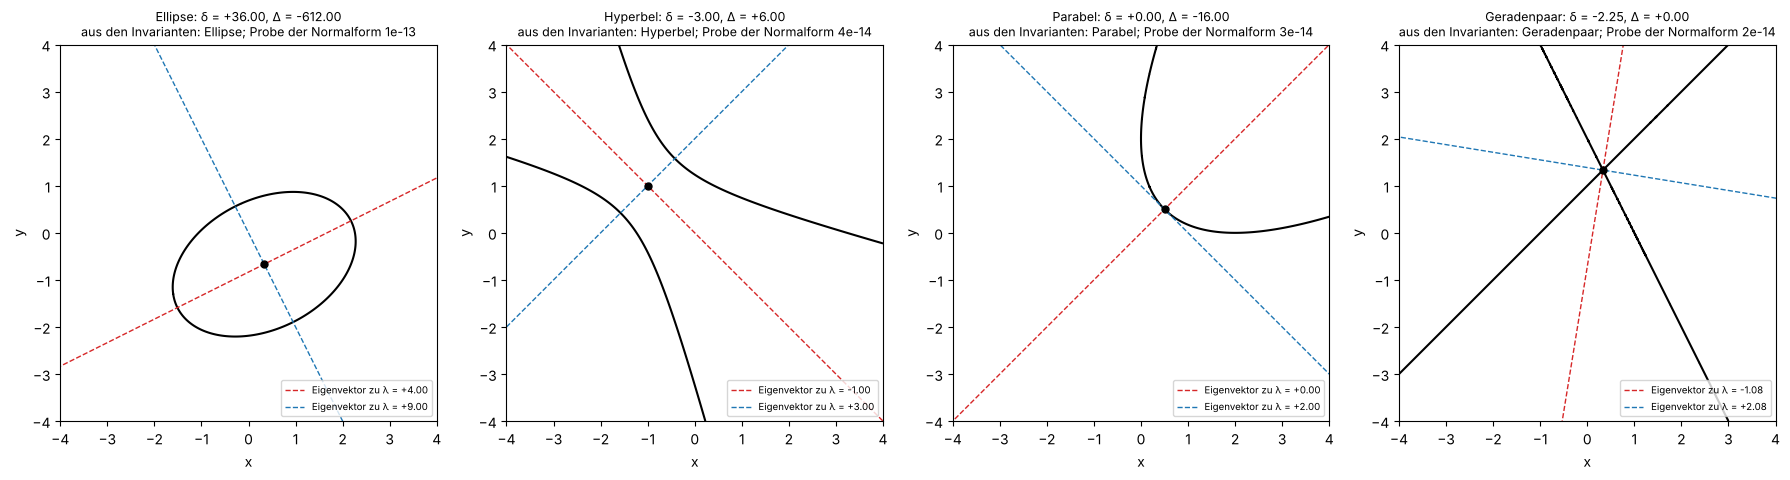

Ellipse     : Normalform +4.000 u² +9.000 v² -17.000 = 0;  Zentrum (0.333, -0.667), Halbachsen 2.062 und 1.374
Hyperbel    : Normalform -1.000 u² +3.000 v² -2.000 = 0;  Zentrum (-1.000, 1.000), Halbachsen 1.414 und 0.816
Parabel     : Normalform +2.000 w₂² +5.657 w₁ = 0, also w₂² = -2.828 w₁;  Scheitel (0.500, 0.500)
Geradenpaar : Normalform -1.081 u² +2.081 v² = 0 (Konstante 0e+00), also v = ±0.721 u;  Schnittpunkt (0.333, 1.333), Winkel zwischen den Geraden 71.57°


In [2]:
conics = {"Ellipse": (5, -4, 8, -6, 12, -12),
          "Hyperbel": (1, 4, 1, -2, 2, -4),
          "Parabel": (1, -2, 1, -4, -4, 4),
          "Geradenpaar": (2, -1, -1, 0, 3, -2)}            # = (x − y + 1)(2x + y − 2)
rng = np.random.default_rng(1)
Xg, Yg = np.meshgrid(np.linspace(-4, 4, 801), np.linspace(-4, 4, 801))
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, (name, coef) in zip(axes, conics.items()):
    A, Ahat = conic_matrices(coef)
    pa = principal_axes(coef)
    ax.contour(Xg, Yg, conic_value(coef, Xg, Yg), levels=[0], colors="black", linewidths=1.5)
    for k_, col in zip(range(2), ["tab:red", "tab:blue"]):
        dvec = pa["R"][:, k_]
        ax.plot(*np.array([pa["x0"] - 8 * dvec, pa["x0"] + 8 * dvec]).T, c=col, lw=1, ls="--",
                label=f"Eigenvektor zu λ = {pa['lam'][k_]:+.2f}")
    ax.plot(*pa["x0"], "o", c="black", ms=5)
    pts = rng.uniform(-4, 4, (1000, 2))
    w = (pts - pa["x0"]) @ pa["R"]                        # Zeilen: wᵀ = (x − x0)ᵀ R
    err = np.max(np.abs(conic_value(coef, pts[:, 0], pts[:, 1]) - pa["normal"](w.T)))
    ax.set_title(f"{name}: δ = {np.linalg.det(A):+.2f}, Δ = {np.linalg.det(Ahat):+.2f}\n"
                 f"aus den Invarianten: {classify_conic(coef)}; Probe der Normalform {err:.0e}", fontsize=9)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

for name, coef in conics.items():
    pa = principal_axes(coef)
    l1, l2 = pa["lam"]
    if name == "Parabel":
        lj, li = pa["lam"][pa["j"]], pa["lin"]
        print(f"{name:12s}: Normalform {lj:+.3f} w₂² {li:+.3f} w₁ = 0, also w₂² = {-li / lj:+.3f} w₁;  "
              f"Scheitel ({pa['x0'][0]:.3f}, {pa['x0'][1]:.3f})")
    elif name == "Geradenpaar":
        s = np.sqrt(-l1 / l2)
        print(f"{name:12s}: Normalform {l1:+.3f} u² {l2:+.3f} v² = 0 (Konstante {abs(pa['const']):.0e}), also v = ±{s:.3f} u;  "
              f"Schnittpunkt ({pa['x0'][0]:.3f}, {pa['x0'][1]:.3f}), Winkel zwischen den Geraden {np.degrees(2 * np.arctan(s)):.2f}°")
    else:
        axes_ = [np.sqrt(abs(pa["const"] / l)) for l in (l1, l2)]
        print(f"{name:12s}: Normalform {l1:+.3f} u² {l2:+.3f} v² {pa['const']:+.3f} = 0;  Zentrum ({pa['x0'][0]:.3f}, {pa['x0'][1]:.3f}), "
              f"Halbachsen {axes_[0]:.3f} und {axes_[1]:.3f}")

##### *2. Der Kegel, die Exzentrizität und die Keplerbahnen*

Ist der Schnitt des Kegels $x^2 + y^2 = z^2$ mit der Ebene $z = 1 + mx$ ein Kegelschnitt mit Exzentrizität $m$, und sind die numerisch berechneten Keplerbahnen Kegelschnitte mit der Exzentrizität $e = |v_0^2 - 1|$ (Herleitung 3)?

Links die Schnitte für $m = 0.5,\ 1,\ 1.6$, gestrichelt ihre Projektionen auf die Ebene $z = 0$: Kegelschnitte mit einem Brennpunkt im Ursprung. Rechts vier Bahnen im Potential $-1/r$, die bei $(1, 0)$ senkrecht mit $v_0 = \sqrt{1 + e}$ starten. Durch die Bahnpunkte wird ein allgemeiner Kegelschnitt gelegt: Der Koeffizientenvektor ist der rechte Singulärvektor zum kleinsten Singulärwert der Matrix mit den Spalten $x^2, xy, y^2, x, y, 1$, also die Lösung von $D\,c \approx 0$ mit $|c| = 1$.

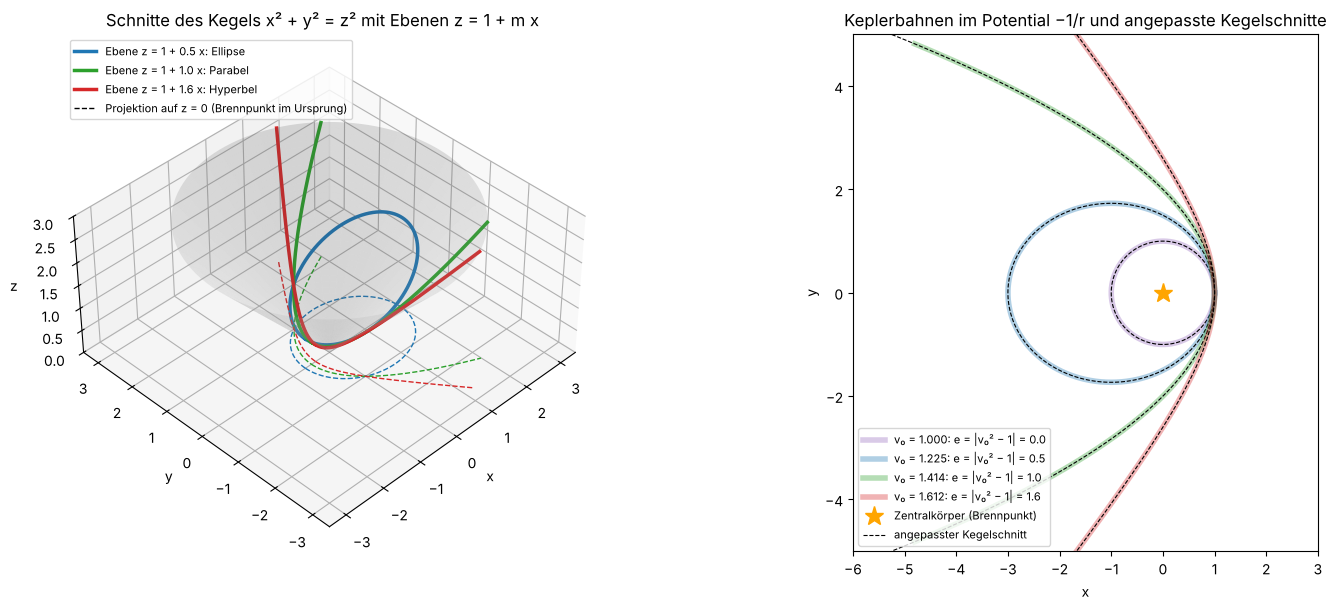

Kegelschnitt mit m = 0.5: Exzentrizität aus der Anpassung 0.5000000000, Typ Ellipse
Kegelschnitt mit m = 1.0: Exzentrizität aus der Anpassung 1.0000000000, Typ Parabel
Kegelschnitt mit m = 1.6: Exzentrizität aus der Anpassung 1.6000000000, Typ Hyperbel
Bahn v₀ = 1.0000: e Theorie 0.000, |A| = 0.0000000000, Drift von A 2e-12, e aus der Anpassung 0.00000017 (Ellipse), Residuum σ_min/σ_max = 9e-13
Bahn v₀ = 1.2247: e Theorie 0.500, |A| = 0.5000000000, Drift von A 6e-11, e aus der Anpassung 0.50000000 (Ellipse), Residuum σ_min/σ_max = 1e-12
Bahn v₀ = 1.4142: e Theorie 1.000, |A| = 1.0000000000, Drift von A 2e-11, e aus der Anpassung 1.00000000 (Parabel), Residuum σ_min/σ_max = 1e-13
Bahn v₀ = 1.6125: e Theorie 1.600, |A| = 1.6000000000, Drift von A 2e-11, e aus der Anpassung 1.60000000 (Hyperbel), Residuum σ_min/σ_max = 6e-14


In [3]:
def kepler_rhs(t, s):
    x, y, vx, vy = s
    r3 = (x * x + y * y) ** 1.5
    return [vx, vy, -x / r3, -y / r3]

def fit_conic(x, y):
    D = np.column_stack([x * x, x * y, y * y, x, y, np.ones_like(x)])
    sv = np.linalg.svd(D, full_matrices=False)
    return sv[2][-1], sv[1][-1] / sv[1][0]                   # Koeffizienten, relativer kleinster Singulärwert

fig = plt.figure(figsize=(16, 6.2))
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
TH, RR = np.meshgrid(np.linspace(0, 2 * np.pi, 120), np.linspace(0, 3.0, 40))
ax3.plot_surface(RR * np.cos(TH), RR * np.sin(TH), RR, color="lightgrey", alpha=0.18, linewidth=0)
cut_rows = []
for m, col, name in [(0.5, "tab:blue", "Ellipse"), (1.0, "tab:green", "Parabel"), (1.6, "tab:red", "Hyperbel")]:
    phi = np.linspace(-np.pi, np.pi, 6001)
    with np.errstate(divide="ignore"):
        r = 1 / (1 - m * np.cos(phi))                     # r(φ) aus Herleitung 3
    r[(r <= 0) | (r > 3.0)] = np.nan
    ax3.plot(r * np.cos(phi), r * np.sin(phi), r, c=col, lw=2.5, label=f"Ebene z = 1 + {m} x: {name}")
    ax3.plot(r * np.cos(phi), r * np.sin(phi), 0 * r, c=col, lw=1, ls="--")
    ok = np.isfinite(r)
    coef, sv = fit_conic(r[ok] * np.cos(phi[ok]), r[ok] * np.sin(phi[ok]))
    cut_rows.append((m, conic_eccentricity(coef), classify_conic(coef)))
ax3.set_xlabel("x"); ax3.set_ylabel("y"); ax3.set_zlabel("z")
ax3.plot([], [], "k--", lw=1, label="Projektion auf z = 0 (Brennpunkt im Ursprung)")
ax3.set_zlim(0, 3.0)
ax3.set_box_aspect((1, 1, 0.5))
ax3.view_init(elev=40, azim=-135)
ax3.set_title("Schnitte des Kegels x² + y² = z² mit Ebenen z = 1 + m x")
ax3.legend(fontsize=8, loc="upper left")

ax2 = fig.add_subplot(1, 2, 2)
Xk, Yk = np.meshgrid(np.linspace(-6, 3, 900), np.linspace(-5, 5, 1000))
kepler_rows = []
for e_target, col in [(0.0, "tab:purple"), (0.5, "tab:blue"), (1.0, "tab:green"), (1.6, "tab:red")]:
    v0 = np.sqrt(1 + e_target)
    T = 2 * np.pi * (1 / (1 - e_target)) ** 1.5 if e_target < 1 else 10.0      # ein Umlauf bzw. Flug nach außen
    sol = solve_ivp(kepler_rhs, [0, T], [1.0, 0.0, 0.0, v0], method="DOP853", rtol=1e-12, atol=1e-12,
                    t_eval=np.linspace(0, T, 3000))
    x, y, vx, vy = sol.y
    L = x * vy - y * vx
    r = np.hypot(x, y)
    Avec = np.array([vy * L - x / r, -vx * L - y / r])                        # Laplace-Runge-Lenz-Vektor
    if e_target >= 1:                                                          # Rückweg durch Zeitumkehr (Spiegelung an der x-Achse)
        x, y = np.r_[x[::-1], x], np.r_[-y[::-1], y]
    coef, sv = fit_conic(x, y)
    keep = (x > -6) & (np.abs(y) < 5)
    ax2.plot(x[keep], y[keep], c=col, lw=4, alpha=0.35, label=f"v₀ = {v0:.3f}: e = |v₀² − 1| = {e_target}")
    ax2.contour(Xk, Yk, conic_value(coef, Xk, Yk), levels=[0], colors="black", linewidths=0.8, linestyles="--")
    kepler_rows.append((v0, e_target, np.linalg.norm(Avec[:, 0]), np.max(np.linalg.norm(Avec - Avec[:, :1], axis=0)),
                        conic_eccentricity(coef), classify_conic(coef), sv))
ax2.plot(0, 0, "*", c="orange", ms=14, label="Zentralkörper (Brennpunkt)")
ax2.plot([], [], "k--", lw=0.8, label="angepasster Kegelschnitt")
ax2.set_xlim(-6, 3); ax2.set_ylim(-5, 5); ax2.set_aspect("equal")
ax2.set_xlabel("x"); ax2.set_ylabel("y")
ax2.set_title("Keplerbahnen im Potential −1/r und angepasste Kegelschnitte")
ax2.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

for m, e_fit, typ in cut_rows:
    print(f"Kegelschnitt mit m = {m}: Exzentrizität aus der Anpassung {e_fit:.10f}, Typ {typ}")
for v0, e_t, e_lrl, drift, e_fit, typ, sv in kepler_rows:
    print(f"Bahn v₀ = {v0:.4f}: e Theorie {e_t:.3f}, |A| = {e_lrl:.10f}, Drift von A {drift:.0e}, "
          f"e aus der Anpassung {e_fit:.8f} ({typ}), Residuum σ_min/σ_max = {sv:.0e}")

##### *3. Quadrikflächen: Signatur und Geraden auf dem Hyperboloid*

Wie sehen die nicht entarteten Quadrikflächen aus, unterscheidet die Signatur der $4\times4$-Matrix $\hat A$ die geregelten von den nicht geregelten, und liegen die Geraden aus Herleitung 4 wirklich auf den Flächen?

Auf dem einschaligen Hyperboloid und dem hyperbolischen Paraboloid sind beide Geradenscharen eingezeichnet (rot und orange). Die Probe setzt 200 Punkte jeder Geraden in die Flächengleichung ein.

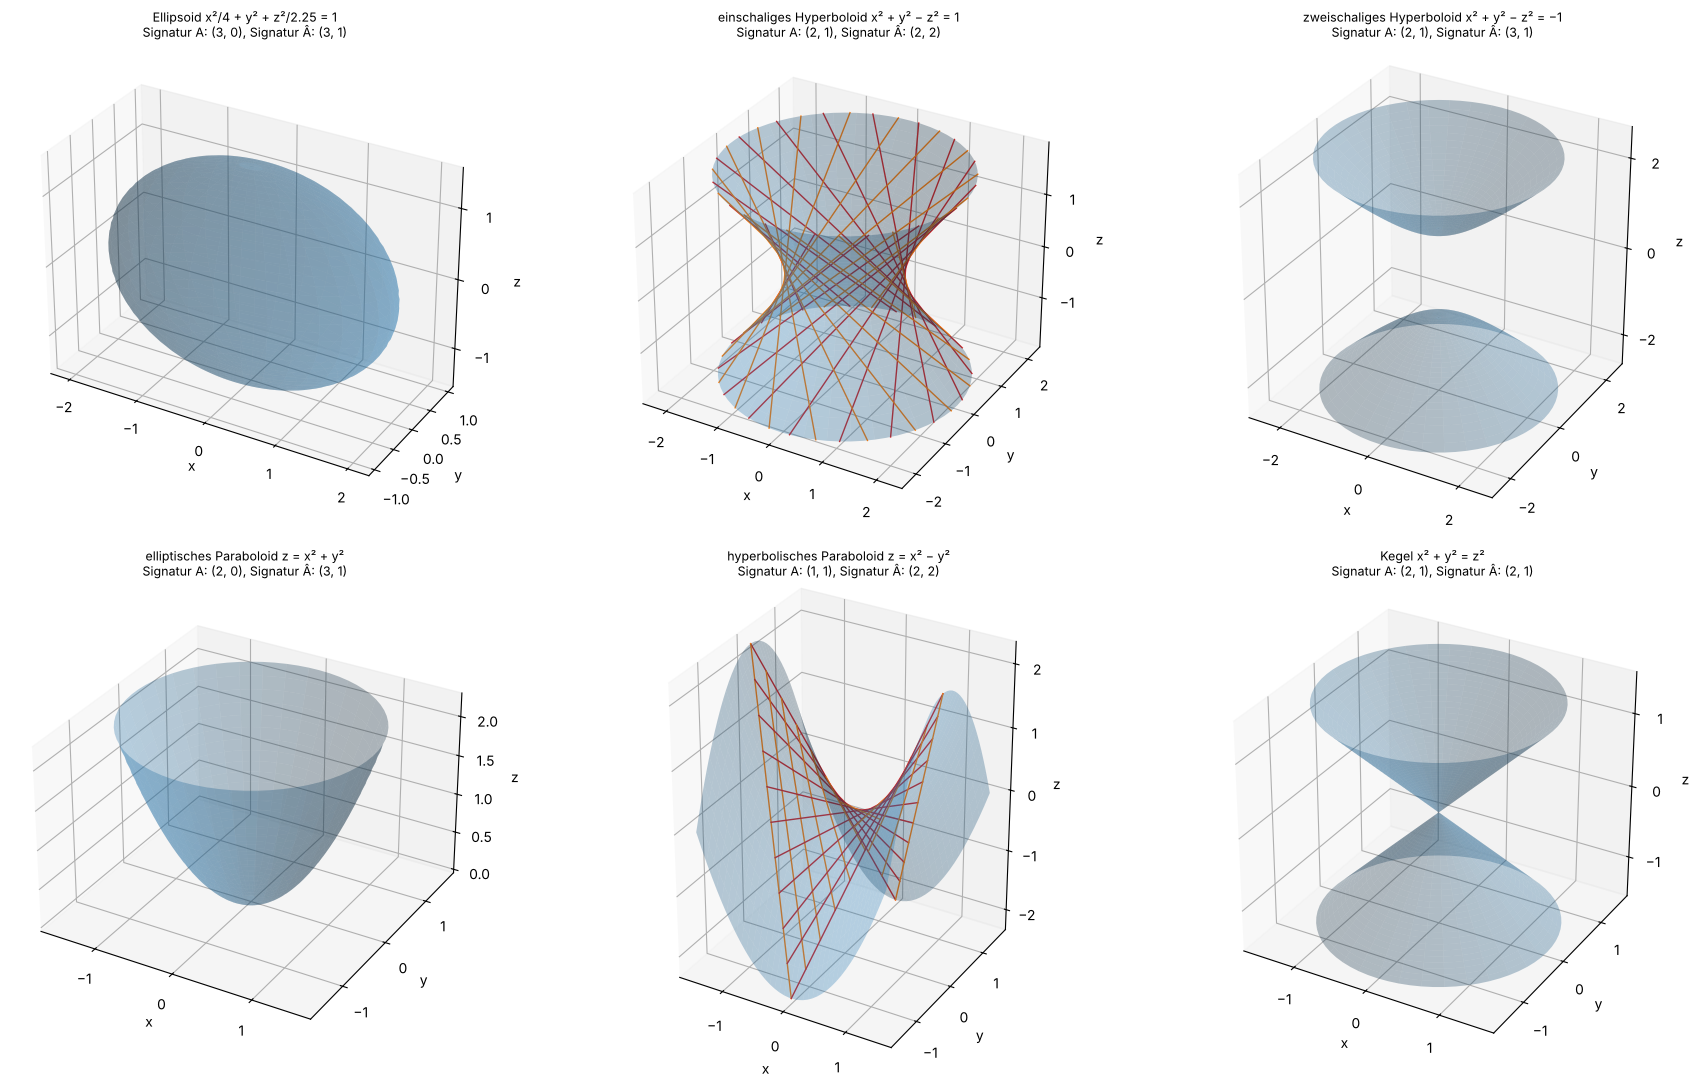

Ellipsoid x²/4 + y² + z²/2.25 = 1              Signatur Â = (3, 1): nicht geregelt, projektiv eine Kugel
einschaliges Hyperboloid x² + y² − z² = 1      Signatur Â = (2, 2): doppelt geregelt
zweischaliges Hyperboloid x² + y² − z² = −1    Signatur Â = (3, 1): nicht geregelt, projektiv eine Kugel
elliptisches Paraboloid z = x² + y²            Signatur Â = (3, 1): nicht geregelt, projektiv eine Kugel
hyperbolisches Paraboloid z = x² − y²          Signatur Â = (2, 2): doppelt geregelt
Kegel x² + y² = z²                             Signatur Â = (2, 1): Rang 3, Kegel (entartet)
Probe der Geraden: größte |F| auf dem Hyperboloid 1.8e-15, auf dem Sattel 4.4e-16


In [4]:
def signature(M, tol=1e-12):
    ev = np.linalg.eigvalsh(M)
    return int(np.sum(ev > tol)), int(np.sum(ev < -tol))

# Â für F(x, y, z) = (x, y, z, 1) Â (x, y, z, 1)ᵀ
quadrics = {
    "Ellipsoid x²/4 + y² + z²/2.25 = 1": np.diag([1 / 4, 1, 1 / 2.25, -1]),
    "einschaliges Hyperboloid x² + y² − z² = 1": np.diag([1, 1, -1, -1.0]),
    "zweischaliges Hyperboloid x² + y² − z² = −1": np.diag([1, 1, -1, 1.0]),
    "elliptisches Paraboloid z = x² + y²": np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, -0.5], [0, 0, -0.5, 0]]),
    "hyperbolisches Paraboloid z = x² − y²": np.array([[1, 0, 0, 0], [0, -1, 0, 0], [0, 0, 0, -0.5], [0, 0, -0.5, 0]]),
    "Kegel x² + y² = z²": np.diag([1, 1, -1, 0.0]),
}
u = np.linspace(0, 2 * np.pi, 70)
fig = plt.figure(figsize=(18, 11))
axs = [fig.add_subplot(2, 3, i + 1, projection="3d") for i in range(6)]
surf = dict(color="tab:blue", alpha=0.30, linewidth=0, shade=True)

U, V = np.meshgrid(u, np.linspace(0, np.pi, 40))
axs[0].plot_surface(2 * np.cos(U) * np.sin(V), np.sin(U) * np.sin(V), 1.5 * np.cos(V), **surf)

U, S = np.meshgrid(u, np.linspace(-1.4, 1.4, 40))
axs[1].plot_surface(np.cosh(S) * np.cos(U), np.cosh(S) * np.sin(U), np.sinh(S), **surf)
t = np.linspace(-np.sinh(1.4), np.sinh(1.4), 200)
res_hyp = 0.0
for sgn, col in [(1, "tab:red"), (-1, "tab:orange")]:
    for ph in np.linspace(0, 2 * np.pi, 16, endpoint=False):
        lx, ly, lz = np.cos(ph) - t * np.sin(ph), np.sin(ph) + t * np.cos(ph), sgn * t
        axs[1].plot(lx, ly, lz, c=col, lw=1)
        res_hyp = max(res_hyp, np.max(np.abs(lx ** 2 + ly ** 2 - lz ** 2 - 1)))

U, S = np.meshgrid(u, np.linspace(0, 1.6, 30))
for sgn in (1, -1):
    axs[2].plot_surface(np.sinh(S) * np.cos(U), np.sinh(S) * np.sin(U), sgn * np.cosh(S), **surf)

U, Rr = np.meshgrid(u, np.linspace(0, 1.5, 30))
axs[3].plot_surface(Rr * np.cos(U), Rr * np.sin(U), Rr ** 2, **surf)

Xs, Ys = np.meshgrid(np.linspace(-1.5, 1.5, 40), np.linspace(-1.5, 1.5, 40))
axs[4].plot_surface(Xs, Ys, Xs ** 2 - Ys ** 2, **surf)
res_sad = 0.0
tt = np.linspace(-1.5, 1.5, 200)
for s_ in np.linspace(-1.5, 1.5, 11):
    for lx, ly, col in [((s_ + tt) / 2, (tt - s_) / 2, "tab:red"),      # x − y = s
                        ((tt + s_) / 2, (s_ - tt) / 2, "tab:orange")]:  # x + y = s
        lz = (lx - ly) * (lx + ly)
        axs[4].plot(lx, ly, lz, c=col, lw=1)
    lx, ly = (s_ + tt) / 2, (tt - s_) / 2
    res_sad = max(res_sad, np.max(np.abs(lx ** 2 - ly ** 2 - s_ * tt)))   # z = s·t entlang der Geraden

U, Rr = np.meshgrid(u, np.linspace(0, 1.5, 30))
for sgn in (1, -1):
    axs[5].plot_surface(Rr * np.cos(U), Rr * np.sin(U), sgn * Rr, **surf)

for ax, (name, Ahat) in zip(axs, quadrics.items()):
    ax.set_box_aspect([np.ptp(lim) for lim in (ax.get_xlim3d(), ax.get_ylim3d(), ax.get_zlim3d())])   # gleiche Maßstäbe
    sA, sAh = signature(Ahat[:3, :3]), signature(Ahat)
    ax.set_title(f"{name}\nSignatur A: {sA}, Signatur Â: {sAh}", fontsize=9)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.locator_params(nbins=5)
fig.tight_layout()
plt.show()

for name, Ahat in quadrics.items():
    sAh = signature(Ahat)
    kind = "Rang 3, Kegel (entartet)" if sum(sAh) < 4 else ("doppelt geregelt" if sAh == (2, 2) else "nicht geregelt, projektiv eine Kugel")
    print(f"{name:46s} Signatur Â = {sAh}: {kind}")
print(f"Probe der Geraden: größte |F| auf dem Hyperboloid {res_hyp:.1e}, auf dem Sattel {res_sad:.1e}")

##### *4. Quadratische Formen in Optimierung und Statistik*

Wie hängt die Konvergenz des Gradientenverfahrens von der Form der Niveau-Ellipsen ab, und liegt in der Mahalanobis-Ellipse $d \le r$ einer Normalverteilung tatsächlich der Anteil $1 - e^{-r^2/2}$ (Herleitung 5)?

Links die Niveaulinien von $f = \tfrac12x^\top Hx$ mit Eigenwerten 1 und 10, um 30° gedreht, und drei Verfahren vom selben Startpunkt. Mitte: Fehler über den Iterationen für $\kappa = 2, 10, 50$, gestrichelt die Vorhersage. Rechts: 20 000 Stichproben einer zweidimensionalen Normalverteilung mit den Ellipsen $d = 1, 2, 3$.

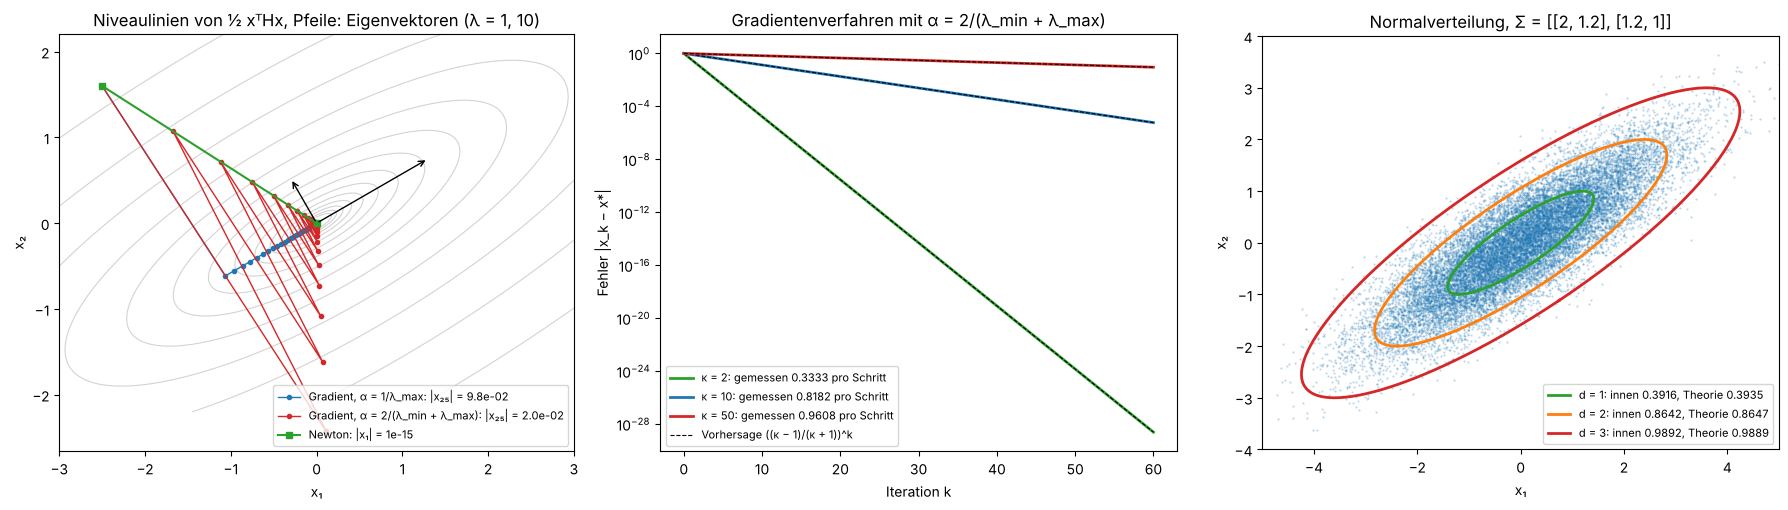

κ =  2: Kontraktion pro Schritt gemessen 0.333333, Theorie (κ − 1)/(κ + 1) = 0.333333; Schritte für Faktor 10⁻⁶: 13
κ = 10: Kontraktion pro Schritt gemessen 0.818182, Theorie (κ − 1)/(κ + 1) = 0.818182; Schritte für Faktor 10⁻⁶: 69
κ = 50: Kontraktion pro Schritt gemessen 0.960784, Theorie (κ − 1)/(κ + 1) = 0.960784; Schritte für Faktor 10⁻⁶: 345
Anteil in der Ellipse d ≤ 1: 0.3916 (Theorie 1 − e^(−r²/2) = 0.3935)
Anteil in der Ellipse d ≤ 2: 0.8642 (Theorie 1 − e^(−r²/2) = 0.8647)
Anteil in der Ellipse d ≤ 3: 0.9892 (Theorie 1 − e^(−r²/2) = 0.9889)


In [5]:
def rotation(deg):
    c, s = np.cos(np.radians(deg)), np.sin(np.radians(deg))
    return np.array([[c, -s], [s, c]])

def gradient_descent(H, x0, alpha, steps):
    xs = [x0]
    for _ in range(steps):
        xs.append(xs[-1] - alpha * H @ xs[-1])
    return np.array(xs)

rng = np.random.default_rng(4)
R30 = rotation(30)
H = R30 @ np.diag([1.0, 10.0]) @ R30.T
x_start = np.array([-2.5, 1.6])
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
Xg, Yg = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-2.2, 2.2, 300))
fval = 0.5 * (H[0, 0] * Xg ** 2 + 2 * H[0, 1] * Xg * Yg + H[1, 1] * Yg ** 2)
axes[0].contour(Xg, Yg, fval, levels=np.geomspace(0.02, 30, 14), colors="lightgrey", linewidths=0.8)
for alpha, lab, col in [(1 / 10, "Gradient, α = 1/λ_max", "tab:blue"), (2 / 11, "Gradient, α = 2/(λ_min + λ_max)", "tab:red")]:
    path = gradient_descent(H, x_start, alpha, 25)
    axes[0].plot(*path.T, "o-", ms=3, lw=1, c=col, label=f"{lab}: |x₂₅| = {np.linalg.norm(path[-1]):.1e}")
x_newton = x_start - np.linalg.solve(H, H @ x_start)
axes[0].plot(*np.array([x_start, x_newton]).T, "s-", c="tab:green", ms=5, label=f"Newton: |x₁| = {np.linalg.norm(x_newton):.0e}")
for k_, col in zip(range(2), ["black", "black"]):
    axes[0].annotate("", xy=R30[:, k_] * (1.5 if k_ == 0 else 0.6), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=col))
axes[0].set_aspect("equal")
axes[0].set_xlabel("x₁"); axes[0].set_ylabel("x₂")
axes[0].set_title("Niveaulinien von ½ xᵀHx, Pfeile: Eigenvektoren (λ = 1, 10)")
axes[0].legend(fontsize=8, loc="lower right")

rates = {}
for kappa, col in [(2, "tab:green"), (10, "tab:blue"), (50, "tab:red")]:
    Hk = np.diag([1.0, kappa])
    path = gradient_descent(Hk, np.array([1.0, 1.0]) / np.sqrt(2), 2 / (1 + kappa), 60)
    err = np.linalg.norm(path, axis=1)
    rho = (kappa - 1) / (kappa + 1)
    rates[kappa] = (np.exp(np.polyfit(np.arange(61), np.log(err), 1)[0]), rho)
    axes[1].semilogy(err, c=col, lw=2, label=f"κ = {kappa}: gemessen {rates[kappa][0]:.4f} pro Schritt")
    axes[1].semilogy(rho ** np.arange(61), "--", c="black", lw=0.8)
axes[1].plot([], [], "k--", lw=0.8, label="Vorhersage ((κ − 1)/(κ + 1))^k")
axes[1].set_xlabel("Iteration k")
axes[1].set_ylabel("Fehler |x_k − x*|")
axes[1].set_title("Gradientenverfahren mit α = 2/(λ_min + λ_max)")
axes[1].legend(fontsize=8)

Sigma = np.array([[2.0, 1.2], [1.2, 1.0]])
samples = rng.standard_normal((20000, 2)) @ np.linalg.cholesky(Sigma).T
d2 = np.einsum("ij,jk,ik->i", samples, np.linalg.inv(Sigma), samples)
axes[2].plot(*samples.T, ".", ms=1, c="tab:blue", alpha=0.3)
lam_s, V_s = np.linalg.eigh(Sigma)
tt = np.linspace(0, 2 * np.pi, 400)
fractions = {}
for r_, col in [(1, "tab:green"), (2, "tab:orange"), (3, "tab:red")]:
    ell = r_ * (V_s @ np.diag(np.sqrt(lam_s)) @ np.array([np.cos(tt), np.sin(tt)]))
    fractions[r_] = (np.mean(d2 <= r_ ** 2), 1 - np.exp(-r_ ** 2 / 2))
    axes[2].plot(*ell, c=col, lw=2, label=f"d = {r_}: innen {fractions[r_][0]:.4f}, Theorie {fractions[r_][1]:.4f}")
axes[2].set_aspect("equal")
axes[2].set_xlim(-5, 5); axes[2].set_ylim(-4, 4)
axes[2].set_xlabel("x₁"); axes[2].set_ylabel("x₂")
axes[2].set_title("Normalverteilung, Σ = [[2, 1.2], [1.2, 1]]")
axes[2].legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

for kappa, (meas, theo) in rates.items():
    print(f"κ = {kappa:2d}: Kontraktion pro Schritt gemessen {meas:.6f}, Theorie (κ − 1)/(κ + 1) = {theo:.6f}; "
          f"Schritte für Faktor 10⁻⁶: {np.log(1e-6) / np.log(theo):.0f}")
for r_, (meas, theo) in fractions.items():
    print(f"Anteil in der Ellipse d ≤ {r_}: {meas:.4f} (Theorie 1 − e^(−r²/2) = {theo:.4f})")

##### *5. Rationale Punkte auf Kegelschnitten: pythagoreische Tripel*

Liefert die Geradenkonstruktion durch $(-1, 0)$ genau alle primitiven pythagoreischen Tripel, wächst ihre Anzahl wie $C/(2\pi)$, und welche Kreise $x^2 + y^2 = n$ haben überhaupt rationale Punkte (Herleitung 6)?

Links die Konstruktion für einige Steigungen $t$ und schwarz alle rationalen Punkte mit Nenner $\le 300$. Rechts die Katheten $(a, b)$ aller primitiven Tripel mit $c \le 20\,000$. Zur Probe werden die Tripel mit $c \le 2000$ zusätzlich durch Durchprobieren aller $a < c$ bestimmt.

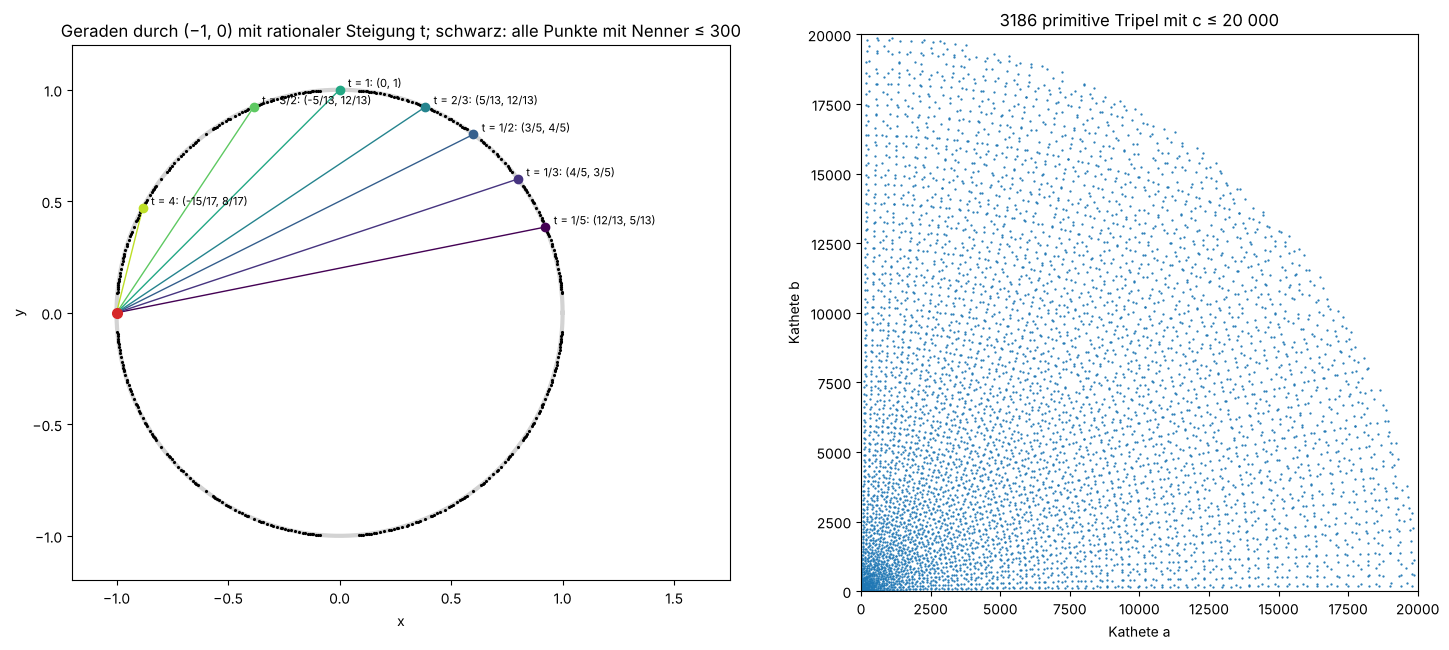

c ≤ 2000: Parametrisierung 319 Tripel, Durchprobieren 319, identisch: True
Primitive Tripel mit c ≤     1,000:     158;  C/(2π) =     159.2
Primitive Tripel mit c ≤    10,000:    1593;  C/(2π) =    1591.5
Primitive Tripel mit c ≤   100,000:   15919;  C/(2π) =   15915.5
Primitive Tripel mit c ≤ 1,000,000:  159139;  C/(2π) =  159154.9

x² + y² = n: rationaler Punkt?
  n =  1: Vorhersage ja   | gefunden: (0/1)² + (1/1)²
  n =  2: Vorhersage ja   | gefunden: (1/1)² + (1/1)²
  n =  3: Vorhersage nein | gefunden: keine Lösung mit Nenner ≤ 300
  n =  4: Vorhersage ja   | gefunden: (0/1)² + (2/1)²
  n =  5: Vorhersage ja   | gefunden: (1/1)² + (2/1)²
  n =  6: Vorhersage nein | gefunden: keine Lösung mit Nenner ≤ 300
  n =  7: Vorhersage nein | gefunden: keine Lösung mit Nenner ≤ 300
  n =  8: Vorhersage ja   | gefunden: (2/1)² + (2/1)²
  n =  9: Vorhersage ja   | gefunden: (0/1)² + (3/1)²
  n = 10: Vorhersage ja   | gefunden: (1/1)² + (3/1)²
  n = 11: Vorhersage nein | gefunden: keine Lösung 

In [6]:
def primitive_triples(C):
    """Alle primitiven Tripel (a < b < c ≤ C) aus der Parametrisierung (n² − m², 2mn, n² + m²)."""
    n = np.arange(2, isqrt(C) + 1)[:, None]
    m = np.arange(1, isqrt(C) + 1)[None, :]
    ok = (m < n) & ((n - m) % 2 == 1) & (np.gcd(m, n) == 1) & (n * n + m * m <= C)
    nn, mm = np.broadcast_to(n, ok.shape)[ok], np.broadcast_to(m, ok.shape)[ok]
    a, b, c = nn * nn - mm * mm, 2 * mm * nn, nn * nn + mm * mm
    return np.column_stack([np.minimum(a, b), np.maximum(a, b), c])

def triples_brute(C):
    out = set()
    for c in range(1, C + 1):
        a = np.arange(1, c, dtype=np.int64)
        b2 = c * c - a * a
        b = np.round(np.sqrt(b2)).astype(np.int64)
        for ai, bi in zip(a[(b * b == b2) & (a < b)], b[(b * b == b2) & (a < b)]):
            if gcd(gcd(int(ai), int(bi)), c) == 1:
                out.add((int(ai), int(bi), c))
    return out

def first_rational_point(nn, Zmax=300):
    """Kleinste Lösung von X² + Y² = n Z² ohne gemeinsamen Teiler mit Z ≤ Zmax, sonst None."""
    for Z in range(1, Zmax + 1):
        X = np.arange(0, isqrt(nn * Z * Z) + 1, dtype=np.int64)
        Y2 = nn * Z * Z - X * X
        Y = np.round(np.sqrt(Y2)).astype(np.int64)
        for x_, y_ in zip(X[Y * Y == Y2], Y[Y * Y == Y2]):
            if gcd(gcd(int(x_), int(y_)), Z) == 1:
                return int(x_), int(y_), Z
    return None

fig, axes = plt.subplots(1, 2, figsize=(15, 6.6))
ax = axes[0]
small = primitive_triples(300)
for a, b, c in small:
    for sx in (1, -1):
        for sy in (1, -1):
            ax.plot([sx * a / c, sx * b / c], [sy * b / c, sy * a / c], ".", c="black", ms=2.5, zorder=3)
tt = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(tt), np.sin(tt), c="lightgrey", lw=3, zorder=1)
for tq, col in zip([Fraction(1, 5), Fraction(1, 3), Fraction(1, 2), Fraction(2, 3), Fraction(1, 1), Fraction(3, 2), Fraction(4, 1)],
                   plt.cm.viridis(np.linspace(0, 0.9, 7))):
    xq, yq = (1 - tq ** 2) / (1 + tq ** 2), 2 * tq / (1 + tq ** 2)
    ax.plot([-1, float(xq)], [0, float(yq)], c=col, lw=1)
    ax.plot(float(xq), float(yq), "o", c=col, ms=6, zorder=4)
    ax.annotate(f"t = {tq}: ({xq}, {yq})", (float(xq), float(yq)), xytext=(6, 2), textcoords="offset points", fontsize=8)
ax.plot(-1, 0, "o", c="tab:red", ms=7, zorder=4)
ax.set_xlim(-1.2, 1.75); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Geraden durch (−1, 0) mit rationaler Steigung t; schwarz: alle Punkte mit Nenner ≤ 300")

big = primitive_triples(20000)
axes[1].plot(big[:, 0], big[:, 1], ".", ms=1.2, c="tab:blue")
axes[1].plot(big[:, 1], big[:, 0], ".", ms=1.2, c="tab:blue")
axes[1].set_xlim(0, 20000); axes[1].set_ylim(0, 20000); axes[1].set_aspect("equal")
axes[1].set_xlabel("Kathete a"); axes[1].set_ylabel("Kathete b")
axes[1].set_title(f"{len(big)} primitive Tripel mit c ≤ 20 000")
fig.tight_layout()
plt.show()

param = {tuple(int(v) for v in row) for row in primitive_triples(2000)}
brute = triples_brute(2000)
print(f"c ≤ 2000: Parametrisierung {len(param)} Tripel, Durchprobieren {len(brute)}, identisch: {param == brute}")
for C in [10 ** 3, 10 ** 4, 10 ** 5, 10 ** 6]:
    print(f"Primitive Tripel mit c ≤ {C:>9,}: {len(primitive_triples(C)):7d};  C/(2π) = {C / (2 * np.pi):9.1f}")
print("\nx² + y² = n: rationaler Punkt?")
for nn in range(1, 16):
    pred = all(e % 2 == 0 for q, e in sp.factorint(nn).items() if q % 4 == 3)
    found = first_rational_point(nn)
    print(f"  n = {nn:2d}: Vorhersage {'ja  ' if pred else 'nein'} | gefunden: "
          f"{f'({found[0]}/{found[2]})² + ({found[1]}/{found[2]})²' if found else 'keine Lösung mit Nenner ≤ 300'}")

##### *6. Die Gruppenaddition auf einer elliptischen Kurve*

Woher kommen die Additionsformeln, wie sieht die Sekanten-Tangenten-Konstruktion über $\mathbb R$ aus, und ist die so definierte Addition wirklich assoziativ?

sympy setzt die Gerade in die Kurve ein und leitet die Steigung der Tangente implizit ab (Herleitung 7). Die Bilder zeigen $P + Q$ und $2P$ auf $y^2 = x^3 - x + 1$ (eine reelle Komponente) und $P + Q$ für zwei Punkte auf dem Ei von $y^2 = x^3 - x$ (zwei Komponenten). Die Assoziativität wird exakt mit Brüchen geprüft: auf allen $16^3$ Tripeln aus den 16 ganzzahligen Punkten von $y^2 = x^3 + 17$.

x³ + ax + b − (λx + ν)² hat die Koeffizienten (x³, x², x, 1):


[1, -lambda**2, a - 2*lambda*nu, b - nu**2]

Steigung der Tangente an y² = x³ + ax + b:


Eq(dy/dx, (a + 3*x**2)/(2*y))

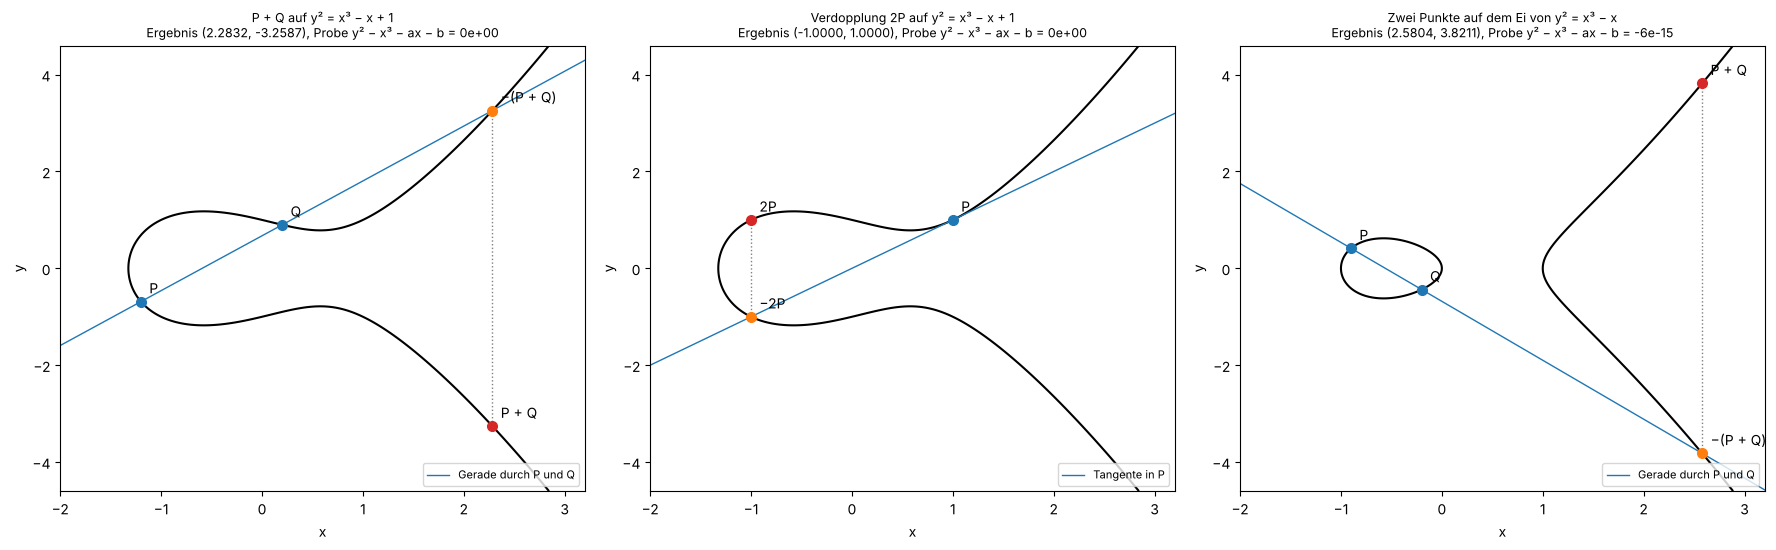

y² = x³ + 17: 16 ganzzahlige Punkte, 4096 Tripel (P + Q) + R = P + (Q + R) exakt geprüft, Abweichungen oder Punkte neben der Kurve: 0; größter Nenner von x: 29 Stellen


In [7]:
xs_, ys_, lam_, nu_, a_, b_ = sp.symbols("x y lambda nu a b")
cubic = sp.Poly(xs_ ** 3 + a_ * xs_ + b_ - (lam_ * xs_ + nu_) ** 2, xs_)
print("x³ + ax + b − (λx + ν)² hat die Koeffizienten (x³, x², x, 1):")
display(cubic.all_coeffs())
print("Steigung der Tangente an y² = x³ + ax + b:")
display(sp.Eq(sp.Symbol("dy/dx"), sp.idiff(ys_ ** 2 - xs_ ** 3 - a_ * xs_ - b_, ys_, xs_)))

def on_curve_point(x, a, b, sign=1):
    return (x, sign * np.sqrt(x ** 3 + a * x + b))

def draw_case(ax, a, b, P, Q, title):
    Xg, Yg = np.meshgrid(np.linspace(-2, 3.2, 700), np.linspace(-4.6, 4.6, 700))
    ax.contour(Xg, Yg, Yg ** 2 - Xg ** 3 - a * Xg - b, levels=[0], colors="black", linewidths=1.5)
    S = ec_add(P, Q, a)
    Rp = ec_neg(S)                                            # dritter Schnittpunkt der Geraden
    lam = (Rp[1] - P[1]) / (Rp[0] - P[0])
    xl = np.linspace(-2, 3.2, 10)
    ax.plot(xl, P[1] + lam * (xl - P[0]), c="tab:blue", lw=1, label="Gerade durch P und Q" if P != Q else "Tangente in P")
    ax.plot([Rp[0], S[0]], [Rp[1], S[1]], c="grey", ls=":", lw=1)
    for pt, name, col in [(P, "P", "tab:blue"), (Q, "Q", "tab:blue"), (Rp, "−(P + Q)" if P != Q else "−2P", "tab:orange"),
                          (S, "P + Q" if P != Q else "2P", "tab:red")]:
        if name == "Q" and P == Q:
            continue
        ax.plot(*pt, "o", c=col, ms=7)
        ax.annotate(name, pt, xytext=(6, 6), textcoords="offset points", fontsize=10)
    ax.set_xlim(-2, 3.2); ax.set_ylim(-4.6, 4.6)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(title + f"\nErgebnis ({S[0]:.4f}, {S[1]:.4f}), Probe y² − x³ − ax − b = {S[1] ** 2 - S[0] ** 3 - a * S[0] - b:.0e}", fontsize=9)
    ax.legend(fontsize=8, loc="lower right")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
draw_case(axes[0], -1, 1, on_curve_point(-1.2, -1, 1, -1), on_curve_point(0.2, -1, 1), "P + Q auf y² = x³ − x + 1")
draw_case(axes[1], -1, 1, (1.0, 1.0), (1.0, 1.0), "Verdopplung 2P auf y² = x³ − x + 1")
draw_case(axes[2], -1, 0, on_curve_point(-0.9, -1, 0), on_curve_point(-0.2, -1, 0, -1), "Zwei Punkte auf dem Ei von y² = x³ − x")
fig.tight_layout()
plt.show()

pts17 = []
for xx in [-2, -1, 2, 4, 8, 43, 52, 5234]:
    yy = isqrt(xx ** 3 + 17)
    assert yy * yy == xx ** 3 + 17
    pts17 += [(Fraction(xx), Fraction(yy)), (Fraction(xx), Fraction(-yy))]
on17 = lambda P: P is O or P[1] ** 2 == P[0] ** 3 + 17
fails, digits = 0, 0
for P in pts17:
    for Q in pts17:
        PQ = ec_add(P, Q, 0)
        for R in pts17:
            lhs, rhs = ec_add(PQ, R, 0), ec_add(P, ec_add(Q, R, 0), 0)
            fails += (lhs != rhs) or not on17(lhs)
            if lhs is not O:
                digits = max(digits, len(str(lhs[0].denominator)))
print(f"y² = x³ + 17: {len(pts17)} ganzzahlige Punkte, {len(pts17) ** 3} Tripel (P + Q) + R = P + (Q + R) exakt geprüft, "
      f"Abweichungen oder Punkte neben der Kurve: {fails}; größter Nenner von x: {digits} Stellen")

##### *7. Rationale Punkte und Höhe: Grad 2, 3 und 4*

Wie viele rationale Punkte mit Höhe $\le C$ haben der Kreis (Grad 2), die elliptische Kurve $y^2 = x^3 - 2$ (Grad 3, Rang 1) und die Fermat-Quartik $x^4 + y^4 = 1$ (Grad 4), und wächst die Höhe der Vielfachen $nP$ wirklich wie $n^2$ (Herleitung 8)?

Auf $y^2 = x^3 - 2$ ist jeder rationale Punkt ein Vielfaches $nP$ von $P = (3, 5)$ (Rang 1, keine Torsion). Die Vielfachen werden exakt mit Brüchen berechnet. Zur Probe werden alle Punkte mit $H(x) \le 20\,000$ unabhängig gesucht: Jeder rationale Punkt hat die Form $x = A/D^2$, $y = B/D^3$, also genügt es, alle $|A| \le 20\,000$ und $D \le 141$ durchzugehen und zu prüfen, ob $A^3 - 2D^6$ ein Quadrat ist. Für die Quartik werden alle $a^4 + b^4 = c^4$ mit $c \le 2000$ gesucht.

Alle Punkte mit H(x) ≤ 20 000 auf y² = x³ − 2 (nur y ≥ 0): ['(3, 5)', '(129/100, 383/1000)']
Zum Vergleich: x(P) = 3, x(2P) = 129/100 , H(x(3P)) = 164323


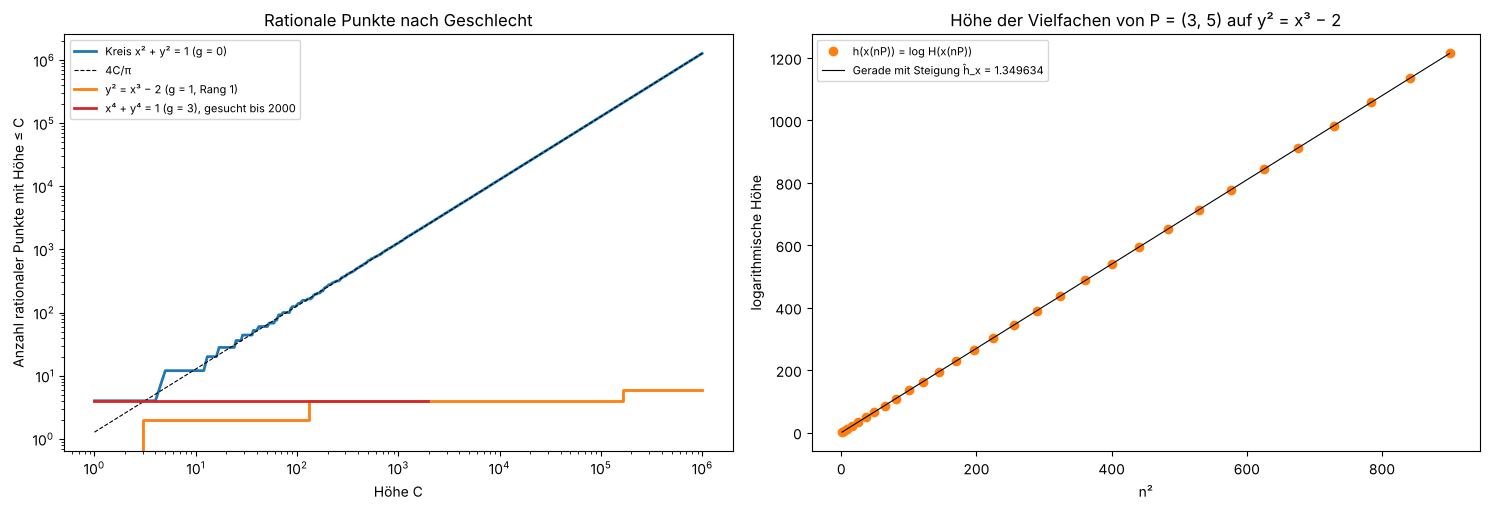

n =  1: H(x(nP)) hat    1 Stellen, h/n² = 1.098612
n =  2: H(x(nP)) hat    3 Stellen, h/n² = 1.214953
n =  3: H(x(nP)) hat    6 Stellen, h/n² = 1.334399
n =  4: H(x(nP)) hat   10 Stellen, h/n² = 1.348363
n = 10: H(x(nP)) hat   59 Stellen, h/n² = 1.346204
n = 30: H(x(nP)) hat  528 Stellen, h/n² = 1.349567
Kanonische Höhe aus der Anpassung: ĥ_x(P) = 1.349634 (Silverman-Normierung ĥ = 0.674817); Abweichung h − ĥ_x n² für n ≥ 6 höchstens 0.593
Kreis: N(10⁶) = 1273116, 4C/π = 1273240;  elliptische Kurve: N(10⁶) = 6;  Quartik: primitive Lösungen von a⁴ + b⁴ = c⁴ mit c ≤ 2000: [(0, 1, 1), (1, 0, 1)]


In [8]:
def height(q):
    return max(abs(q.numerator), q.denominator)

# Grad 3: Vielfache von P = (3, 5) auf y² = x³ − 2
P = (Fraction(3), Fraction(5))
mult, nP = [], O
for n in range(1, 31):
    nP = ec_add(nP, P, 0)
    assert nP[1] ** 2 == nP[0] ** 3 - 2
    mult.append((n, height(nP[0]), log(height(nP[0]))))
ns = np.array([m_[0] for m_ in mult])
hs = np.array([m_[2] for m_ in mult])
slope, icpt = np.polyfit(ns[5:] ** 2, hs[5:], 1)

# unabhängige Suche: x = A/D², A³ − 2D⁶ = B²
found = []
for D in range(1, isqrt(20000) + 1):
    A = np.arange(-20000, 20001, dtype=np.int64)
    rhs = A ** 3 - 2 * D ** 6
    ok = rhs >= 0
    B = np.round(np.sqrt(rhs[ok].astype(float))).astype(np.int64)
    for A_, B_ in zip(A[ok][B * B == rhs[ok]], B[B * B == rhs[ok]]):
        if gcd(int(A_), D) == 1:
            found.append((Fraction(int(A_), D * D), Fraction(int(B_), D ** 3)))
print("Alle Punkte mit H(x) ≤ 20 000 auf y² = x³ − 2 (nur y ≥ 0):", [f"({q[0]}, {q[1]})" for q in found])
print("Zum Vergleich: x(P) = 3, x(2P) =", ec_add(P, P, 0)[0], ", H(x(3P)) =", mult[2][1])

# Grad 2: Kreis, acht Punkte pro primitivem Tripel plus (±1, 0), (0, ±1)
hyp = np.sort(primitive_triples(10 ** 6)[:, 2])
Cs = np.unique(np.geomspace(1, 10 ** 6, 400).astype(int))
N_circle = 4 + 8 * np.searchsorted(hyp, Cs, side="right")
# Grad 3: ±nP mit H(x(nP)) ≤ C
H_mult = np.array([m_[1] for m_ in mult], dtype=object)
N_ell = np.array([2 * sum(1 for h_ in H_mult if h_ <= C) for C in Cs])
# Grad 4: a⁴ + b⁴ = c⁴ mit 0 ≤ a ≤ c ≤ 2000
quartic = []
for c in range(1, 2001):
    a = np.arange(0, c + 1, dtype=np.int64)
    b4 = c ** 4 - a ** 4
    b = np.round(b4.astype(float) ** 0.25).astype(np.int64)
    for a_, b_ in zip(a[b ** 4 == b4], b[b ** 4 == b4]):
        if gcd(gcd(int(a_), int(b_)), c) == 1:
            quartic.append((int(a_), int(b_), c))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].loglog(Cs, N_circle, c="tab:blue", lw=2, label="Kreis x² + y² = 1 (g = 0)")
axes[0].loglog(Cs, 4 * Cs / np.pi, "--", c="black", lw=0.8, label="4C/π")
axes[0].loglog(Cs, N_ell, c="tab:orange", lw=2, drawstyle="steps-post", label="y² = x³ − 2 (g = 1, Rang 1)")
axes[0].loglog(Cs[Cs <= 2000], np.full(np.sum(Cs <= 2000), 4), c="tab:red", lw=2, label="x⁴ + y⁴ = 1 (g = 3), gesucht bis 2000")
axes[0].set_xlabel("Höhe C")
axes[0].set_ylabel("Anzahl rationaler Punkte mit Höhe ≤ C")
axes[0].set_title("Rationale Punkte nach Geschlecht")
axes[0].legend(fontsize=8)
axes[1].plot(ns ** 2, hs, "o", c="tab:orange", label="h(x(nP)) = log H(x(nP))")
axes[1].plot(ns ** 2, slope * ns ** 2 + icpt, c="black", lw=0.8, label=f"Gerade mit Steigung ĥ_x = {slope:.6f}")
axes[1].set_xlabel("n²")
axes[1].set_ylabel("logarithmische Höhe")
axes[1].set_title("Höhe der Vielfachen von P = (3, 5) auf y² = x³ − 2")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

for n, H_, h_ in mult[:4] + mult[9:10] + mult[-1:]:
    print(f"n = {n:2d}: H(x(nP)) hat {len(str(H_)):4d} Stellen, h/n² = {h_ / n ** 2:.6f}")
print(f"Kanonische Höhe aus der Anpassung: ĥ_x(P) = {slope:.6f} (Silverman-Normierung ĥ = {slope / 2:.6f}); "
      f"Abweichung h − ĥ_x n² für n ≥ 6 höchstens {np.max(np.abs(hs[5:] - slope * ns[5:] ** 2)):.3f}")
print(f"Kreis: N(10⁶) = {N_circle[-1]}, 4C/π = {4e6 / np.pi:.0f};  elliptische Kurve: N(10⁶) = {N_ell[-1]};  "
      f"Quartik: primitive Lösungen von a⁴ + b⁴ = c⁴ mit c ≤ 2000: {quartic}")

##### *8. Elliptische Kurven über endlichen Körpern: Hasse und Sato-Tate*

Wie sieht eine elliptische Kurve über $\mathbb F_p$ aus, bleibt $a_p = p + 1 - \#E(\mathbb F_p)$ innerhalb der Hasse-Schranke $\pm2\sqrt p$, und sind die normierten Werte $a_p/2\sqrt p$ nach dem Halbkreis verteilt (Herleitung 9)?

Gezählt wird mit dem Legendre-Symbol für alle Primzahlen $5 \le p < 30\,000$, für die Kurve $y^2 = x^3 + x + 1$ ohne komplexe Multiplikation und für $y^2 = x^3 - x$ mit komplexer Multiplikation. Über $\mathbb F_{61}$ werden zusätzlich alle Tripel von Punkten auf Assoziativität geprüft.

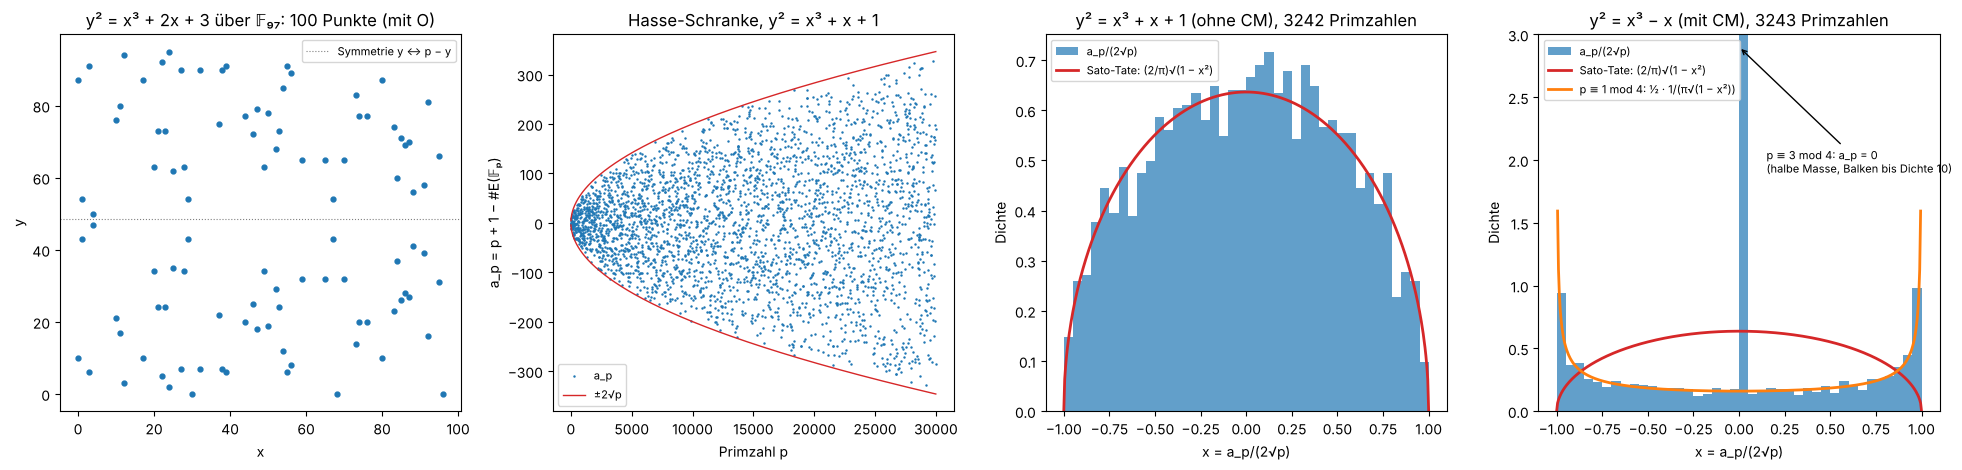

y² = x³ + x + 1 (ohne CM) : max |a_p|/(2√p) = 0.9997;  ⟨x²⟩ = 0.2440 (Sato-Tate 0.25), ⟨x⁴⟩ = 0.1211 (0.125);  Anteil a_p = 0: 0.004, davon bei p ≡ 3 mod 4: 0.006
y² = x³ − x (mit CM)      : max |a_p|/(2√p) = 0.9999;  ⟨x²⟩ = 0.2449 (Sato-Tate 0.25), ⟨x⁴⟩ = 0.1824 (0.125);  Anteil a_p = 0: 0.503, davon bei p ≡ 3 mod 4: 1.000


y² = x³ + 2x + 3 über 𝔽₆₁: 68 Punkte, Assoziativität auf allen 314432 Tripeln, Verstöße: 0; größte Punktordnung 68, die Gruppe ist zyklisch ({2: 2, 17: 1})


In [9]:
primes = np.array(list(sp.primerange(5, 30000)))
curves = {"y² = x³ + x + 1 (ohne CM)": (1, 1), "y² = x³ − x (mit CM)": (-1, 0)}
ap = {}
for name, (a, b) in curves.items():
    ps = [p for p in primes if (4 * a ** 3 + 27 * b ** 2) % p != 0]
    ap[name] = (np.array(ps), np.array([p + 1 - ec_count(a, b, p) for p in ps]))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
pts = ec_points(2, 3, 97)
axes[0].plot([q[0] for q in pts[1:]], [q[1] for q in pts[1:]], "o", ms=3.5, c="tab:blue")
axes[0].axhline(97 / 2, c="grey", lw=0.8, ls=":", label="Symmetrie y ↔ p − y")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[0].set_title(f"{curve_str(2, 3)} über {field(97)}: {len(pts)} Punkte (mit O)")
axes[0].legend(fontsize=8, loc="upper right")

ps, a1 = ap["y² = x³ + x + 1 (ohne CM)"]
axes[1].plot(ps, a1, ".", ms=1.5, c="tab:blue", label="a_p")
axes[1].plot(ps, 2 * np.sqrt(ps), c="tab:red", lw=1, label="±2√p")
axes[1].plot(ps, -2 * np.sqrt(ps), c="tab:red", lw=1)
axes[1].set_xlabel("Primzahl p"); axes[1].set_ylabel("a_p = p + 1 − #E(𝔽ₚ)")
axes[1].set_title("Hasse-Schranke, y² = x³ + x + 1")
axes[1].legend(fontsize=8, loc="lower left")

xx = np.linspace(-1, 1, 400)
moments = {}
for ax, (name, (ps_, a_p)) in zip(axes[2:], ap.items()):
    xn = a_p / (2 * np.sqrt(ps_))
    moments[name] = (np.mean(xn ** 2), np.mean(xn ** 4), np.max(np.abs(xn)), np.mean(a_p == 0),
                     np.mean(a_p[ps_ % 4 == 3] == 0), len(ps_))
    ax.hist(xn, bins=40, range=(-1, 1), density=True, color="tab:blue", alpha=0.7, label="a_p/(2√p)")
    ax.plot(xx, 2 / np.pi * np.sqrt(1 - xx ** 2), c="tab:red", lw=2, label="Sato-Tate: (2/π)√(1 − x²)")
    ax.set_xlabel("x = a_p/(2√p)"); ax.set_ylabel("Dichte")
    ax.set_title(f"{name}, {len(ps_)} Primzahlen")
xi = np.linspace(-0.995, 0.995, 400)
axes[3].plot(xi, 0.5 / (np.pi * np.sqrt(1 - xi ** 2)), c="tab:orange", lw=2, label="p ≡ 1 mod 4: ½ · 1/(π√(1 − x²))")
axes[3].annotate("p ≡ 3 mod 4: a_p = 0\n(halbe Masse, Balken bis Dichte 10)", (0.0, 2.9), xytext=(0.15, 1.9), fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="black"))
axes[3].set_ylim(0, 3)
for ax in axes[2:]:
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

for name, (m2, m4, mx, z, z3, cnt) in moments.items():
    print(f"{name:26s}: max |a_p|/(2√p) = {mx:.4f};  ⟨x²⟩ = {m2:.4f} (Sato-Tate 0.25), ⟨x⁴⟩ = {m4:.4f} (0.125);  "
          f"Anteil a_p = 0: {z:.3f}, davon bei p ≡ 3 mod 4: {z3:.3f}")

a, b, p = 2, 3, 61
E61 = ec_points(a, b, p)
bad = sum(ec_add(ec_add(P, Q, a, p), R, a, p) != ec_add(P, ec_add(Q, R, a, p), a, p)
          for P in E61 for Q in E61 for R in E61)
orders = [ec_order(P, a, p) for P in E61[1:]]
print(f"{curve_str(a, b)} über {field(p)}: {len(E61)} Punkte, Assoziativität auf allen {len(E61) ** 3} Tripeln, Verstöße: {bad}; "
      f"größte Punktordnung {max(orders)}, die Gruppe ist {'zyklisch' if max(orders) == len(E61) else 'nicht zyklisch'} "
      f"({sp.factorint(len(E61))})")

##### *9. ECDH und das diskrete Logarithmusproblem*

Wie läuft ein Schlüsselaustausch auf einer Kurve über $\mathbb F_p$, und wächst der Aufwand der klassischen Angriffe wirklich wie $\sqrt N$ (Herleitung 10)?

Für Primzahlen $p$ mit 10 bis 22 Bit wird je eine Kurve mit Primzahlordnung $N$ gesucht und sechsmal ein zufälliger Logarithmus berechnet: durch Durchprobieren (bis 18 Bit), mit Baby-Step-Giant-Step und mit Pollard-Rho (additive Irrfahrt mit 20 Sprüngen, Floyds Zyklensuche). Gezählt werden die Gruppenoperationen. Links die Vielfachen $kG$ auf einer kleinen Kurve, nach $k$ gefärbt. Am Ende dasselbe in echter Größe auf der Kurve secp256k1 von Bitcoin.

Kurve y² = x³ + 22391x + 2830 über 𝔽₅₁₁₉₇, Ordnung N = 50993 (prim), Erzeuger G = (26947, 21739)
Alice: geheim a = 3591, öffentlich A = aG = (18095, 50361)
Bob:   geheim b = 24827, öffentlich B = bG = (26477, 29245)
aB = (34504, 48161), bA = (34504, 48161), abG = (34504, 48161)


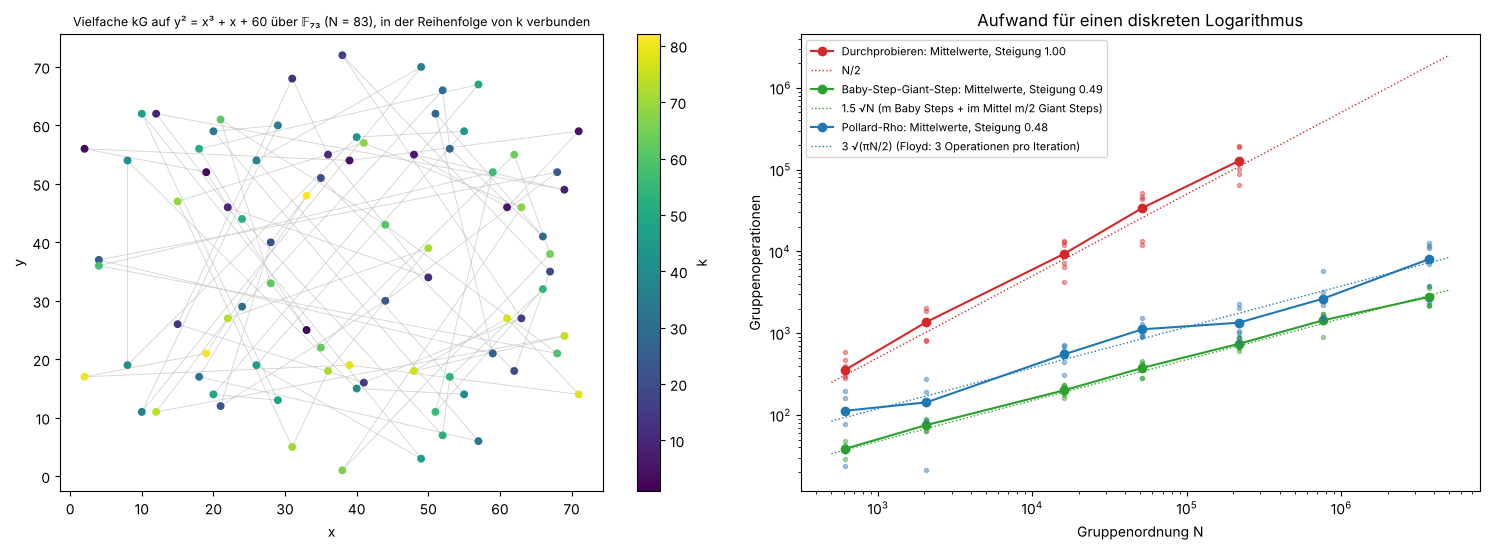

Durchprobieren       : Steigung der Mittelwerte 1.000;  gemessen / Vorhersage (N/2) im Mittel 1.23 über 30 Logarithmen
Baby-Step-Giant-Step : Steigung der Mittelwerte 0.494;  gemessen / Vorhersage (1.5 √N) im Mittel 1.06 über 42 Logarithmen
Pollard-Rho          : Steigung der Mittelwerte 0.484;  gemessen / Vorhersage (3 √(πN/2)) im Mittel 1.03 über 42 Logarithmen

secp256k1: G auf der Kurve: True;  N prim: True;  N·G = O: True
Ein Skalarprodukt mit 256-Bit-Schlüssel: 256 Verdopplungen und 142 Additionen, 13.4 ms in reinem Python
Gemeinsames Geheimnis gleich: True
Pollard-Rho bräuchte √(πN/2) = 4.26e+38 Operationen, bei 10¹² Operationen pro Sekunde 1.4e+19 Jahre


In [10]:
rng9 = random.Random(9)

def random_prime_order_curve(bits, rng):
    """Zufällige Kurve y² = x³ + ax + b über 𝔽ₚ (p mit etwa `bits` Bit) mit Primzahlordnung N ≠ p, und ein Erzeuger G."""
    while True:
        p = int(sp.nextprime(rng.randrange(2 ** (bits - 1), 2 ** bits)))
        a, b = rng.randrange(p), rng.randrange(p)
        if (4 * a ** 3 + 27 * b ** 2) % p == 0:
            continue
        N = ec_count(a, b, p)
        if N == p or not sp.isprime(N):
            continue
        while True:                                           # jeder Punkt ≠ O erzeugt die Gruppe
            x = rng.randrange(p)
            r = (x ** 3 + a * x + b) % p
            if r and pow(r, (p - 1) // 2, p) == 1:
                return p, a, b, N, (x, int(sp.sqrt_mod(r, p)))

def dlog_brute(G, Q, a, p):
    R, k = G, 1
    while R != Q:
        R, k = ec_add(R, G, a, p), k + 1
    return k, k - 1

def dlog_bsgs(G, Q, N, a, p):
    m = isqrt(N - 1) + 1
    table, R = {}, O
    for j in range(m):                                        # Baby Steps jG
        table.setdefault(R, j)
        R = ec_add(R, G, a, p)
    giant, gamma, ops = ec_neg(R, p), Q, m                    # R = mG
    for i in range(m + 1):                                    # Giant Steps Q − imG
        if gamma in table:
            return (i * m + table[gamma]) % N, ops
        gamma, ops = ec_add(gamma, giant, a, p), ops + 1

def dlog_rho(G, Q, N, a, p, rng, r=20):
    while True:
        cs, ds = [rng.randrange(N) for _ in range(r)], [rng.randrange(N) for _ in range(r)]
        M = [ec_add(ec_mul(c, G, a, p), ec_mul(d, Q, a, p), a, p) for c, d in zip(cs, ds)]
        def step(X, al, be):
            j = 0 if X is O else X[0] % r
            return ec_add(X, M[j], a, p), (al + cs[j]) % N, (be + ds[j]) % N
        al0, be0 = rng.randrange(N), rng.randrange(N)
        X0 = ec_add(ec_mul(al0, G, a, p), ec_mul(be0, Q, a, p), a, p)
        T, H_, ops = (X0, al0, be0), (X0, al0, be0), 0
        while True:                                           # Floyd: Schildkröte ein Schritt, Hase zwei
            T, H_, ops = step(*T), step(*step(*H_)), ops + 3
            if T[0] == H_[0]:
                break
        if (T[2] - H_[2]) % N:
            return (H_[1] - T[1]) * pow(T[2] - H_[2], -1, N) % N, ops

# Spielzeug-ECDH
p, a, b, N, G = random_prime_order_curve(16, rng9)
sa, sb = rng9.randrange(1, N), rng9.randrange(1, N)
A_pub, B_pub = ec_mul(sa, G, a, p), ec_mul(sb, G, a, p)
print(f"Kurve {curve_str(a, b)} über {field(p)}, Ordnung N = {N} (prim), Erzeuger G = {G}")
print(f"Alice: geheim a = {sa}, öffentlich A = aG = {A_pub}")
print(f"Bob:   geheim b = {sb}, öffentlich B = bG = {B_pub}")
print(f"aB = {ec_mul(sa, B_pub, a, p)}, bA = {ec_mul(sb, A_pub, a, p)}, abG = {ec_mul(sa * sb % N, G, a, p)}")

# Skalierung der Angriffe
results = {"Durchprobieren": [], "Baby-Step-Giant-Step": [], "Pollard-Rho": []}
for bits in range(10, 23, 2):
    p, a, b, N, G = random_prime_order_curve(bits, rng9)
    for _ in range(6):
        k = rng9.randrange(1, N)
        Q = ec_mul(k, G, a, p)
        if bits <= 18:
            k0, ops = dlog_brute(G, Q, a, p); assert k0 == k
            results["Durchprobieren"].append((N, ops))
        k1, ops = dlog_bsgs(G, Q, N, a, p); assert k1 == k
        results["Baby-Step-Giant-Step"].append((N, ops))
        k2, ops = dlog_rho(G, Q, N, a, p, rng9); assert k2 == k
        results["Pollard-Rho"].append((N, ops))

ps_, as_, bs_, Ns_, Gs_ = random_prime_order_curve(7, random.Random(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
multiples = [ec_mul(k, Gs_, as_, ps_) for k in range(1, Ns_)]
axes[0].plot([q[0] for q in multiples], [q[1] for q in multiples], c="lightgrey", lw=0.6, zorder=1)
sc = axes[0].scatter([q[0] for q in multiples], [q[1] for q in multiples], c=np.arange(1, Ns_), cmap="viridis", s=22, zorder=2)
fig.colorbar(sc, ax=axes[0], label="k")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[0].set_title(f"Vielfache kG auf {curve_str(as_, bs_)} über {field(ps_)} (N = {Ns_}), in der Reihenfolge von k verbunden", fontsize=9)
slopes, refs = {}, {"Durchprobieren": lambda N_: N_ / 2, "Baby-Step-Giant-Step": lambda N_: 1.5 * np.sqrt(N_),
                    "Pollard-Rho": lambda N_: 3 * np.sqrt(np.pi * N_ / 2)}
ref_labels = {"Durchprobieren": "N/2", "Baby-Step-Giant-Step": "1.5 √N (m Baby Steps + im Mittel m/2 Giant Steps)",
              "Pollard-Rho": "3 √(πN/2) (Floyd: 3 Operationen pro Iteration)"}
Nref = np.geomspace(500, 5e6, 50)
for (name, rows), col in zip(results.items(), ["tab:red", "tab:green", "tab:blue"]):
    Nn, ops = np.array(rows, dtype=float).T
    Nu = np.unique(Nn)
    means = np.array([ops[Nn == v].mean() for v in Nu])
    slopes[name] = np.polyfit(np.log(Nu), np.log(means), 1)[0]
    axes[1].loglog(Nn, ops, "o", c=col, ms=3, alpha=0.4)
    axes[1].loglog(Nu, means, "o-", c=col, ms=6, lw=1.5, label=f"{name}: Mittelwerte, Steigung {slopes[name]:.2f}")
    axes[1].loglog(Nref, refs[name](Nref), ":", c=col, lw=1, label=ref_labels[name])
axes[1].set_xlabel("Gruppenordnung N")
axes[1].set_ylabel("Gruppenoperationen")
axes[1].set_title("Aufwand für einen diskreten Logarithmus")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
for name, rows in results.items():
    Nn, ops = np.array(rows, dtype=float).T
    print(f"{name:21s}: Steigung der Mittelwerte {slopes[name]:.3f};  gemessen / Vorhersage ({ref_labels[name].split(' (')[0]}) "
          f"im Mittel {np.mean(ops / refs[name](Nn)):.2f} über {len(ops)} Logarithmen")

# secp256k1 (Bitcoin): y² = x³ + 7 über 𝔽ₚ mit p = 2²⁵⁶ − 2³² − 977
p256 = 2 ** 256 - 2 ** 32 - 977
G256 = (0x79BE667EF9DCBBAC55A06295CE870B07029BFCDB2DCE28D959F2815B16F81798,
        0x483ADA7726A3C4655DA4FBFC0E1108A8FD17B448A68554199C47D08FFB10D4B8)
N256 = 0xFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFEBAAEDCE6AF48A03BBFD25E8CD0364141
print(f"\nsecp256k1: G auf der Kurve: {(G256[1] ** 2 - G256[0] ** 3 - 7) % p256 == 0};  N prim: {sp.isprime(N256)};  "
      f"N·G = O: {ec_mul(N256, G256, 0, p256) is O}")
sa, sb = rng9.randrange(1, N256), rng9.randrange(1, N256)
t0 = time.perf_counter()
A_pub = ec_mul(sa, G256, 0, p256)
t_mul = time.perf_counter() - t0
B_pub = ec_mul(sb, G256, 0, p256)
print(f"Ein Skalarprodukt mit {sa.bit_length()}-Bit-Schlüssel: {sa.bit_length()} Verdopplungen und {bin(sa).count('1')} Additionen, "
      f"{1e3 * t_mul:.1f} ms in reinem Python")
print(f"Gemeinsames Geheimnis gleich: {ec_mul(sa, B_pub, 0, p256) == ec_mul(sb, A_pub, 0, p256)}")
ops_rho = np.sqrt(np.pi * N256 / 2)
print(f"Pollard-Rho bräuchte √(πN/2) = {ops_rho:.2e} Operationen, bei 10¹² Operationen pro Sekunde {ops_rho / 1e12 / 3.156e7:.1e} Jahre")

##### *10. Shors Algorithmus für den diskreten Logarithmus auf einer winzigen Kurve*

Findet die Simulation von Shors Algorithmus den geheimen Exponenten $k$ in $Q = kP$, wo genau kommt die Quanten-Fourier-Transformation ins Spiel, und was ändert sich mit Registern der Größe $2^n$ statt $N$ (Herleitung 11)?

Der Zustandsvektor der drei Register wird vollständig gespeichert ($N^3$ Amplituden). Das dritte Register enthält den Punkt $aP + bQ$, berechnet mit der Gruppenaddition aus dem Werkzeug-Abschnitt. Der geheime Exponent $k$ geht nur in $Q = kP$ ein und dient am Ende zur Kontrolle; der Algorithmus selbst sieht nur Punkte. Die Bilder zeigen, Schritt für Schritt: die Funktion $f(a, b) = aP + bQ$, die Amplituden nach der Messung des dritten Registers, die Verteilung nach der QFT und dieselbe Verteilung mit Registern aus $n = \lceil\log_2 N\rceil$ Qubits. Zum Schluss wird die QFT aus Hadamard-, Phasen- und SWAP-Gattern zusammengesetzt und mit der diskreten Fourier-Transformation verglichen.

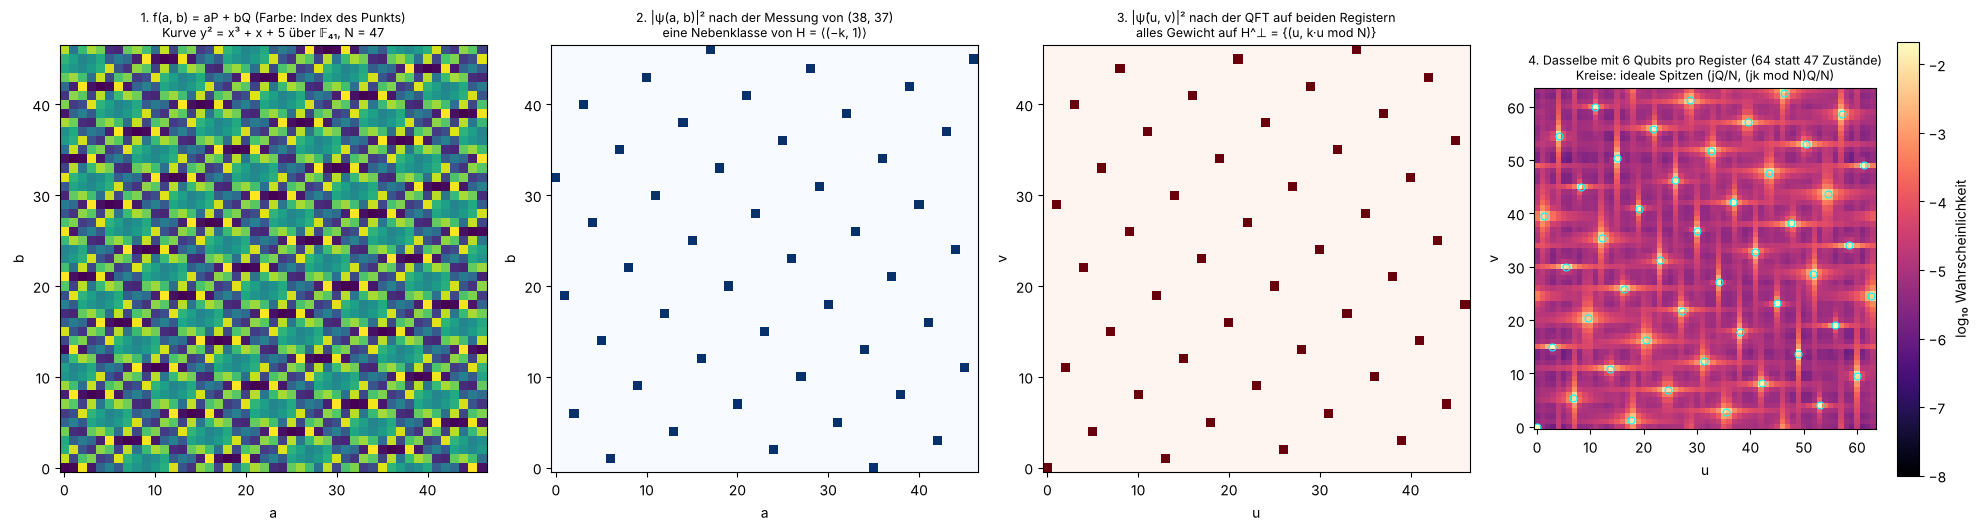

Kurve y² = x³ + x + 5 über 𝔽₄₁: N = 47 (prim); P = (0, 13), Q = (36, 30); geheim k = 29
Gemessen im dritten Register: (38, 37); Wahrscheinlichkeit auf der Geraden v ≡ k·u: 1.000000000000000
Verteilung mit und ohne Messung des dritten Registers, größte Differenz: 3.1e-17
12 Messungen (u, v) → k = v·u⁻¹ mod N: (9,26)→29, (38,21)→29, (7,15)→29, (24,38)→29, (6,33)→29, (32,35)→29, (39,3)→29, (19,34)→29, (44,7)→29, (38,21)→29, (15,12)→29, (27,31)→29
Erfolgswahrscheinlichkeit pro Durchlauf: ideal 0.9787 (Theorie 1 − 1/N = 0.9787)
  mit 6 Qubits pro Register: Erfolg nach Rundung 0.7391  (Gesamtwahrscheinlichkeit 1.000000000000)
  mit 7 Qubits pro Register: Erfolg nach Rundung 0.8219  (Gesamtwahrscheinlichkeit 1.000000000000)
  mit 8 Qubits pro Register: Erfolg nach Rundung 0.9097  (Gesamtwahrscheinlichkeit 1.000000000000)


  mit 9 Qubits pro Register: Erfolg nach Rundung 0.9415  (Gesamtwahrscheinlichkeit 1.000000000000)

QFT-Schaltung mit 6 Qubits: 6 Hadamard, 15 kontrollierte Phasen, 3 SWAPs; größte Abweichung von der DFT-Matrix 5.1e-15
Für eine 256-Bit-Kurve (Roetteler et al. 2017): 2330 logische Qubits, Toffoli-Gatter höchstens (448 log₂n + 4090) n³ = 1.29e+11; die QFT auf 257 Qubits hat dagegen nur 32,896 kontrollierte Phasen


In [11]:
rng10 = np.random.default_rng(10)

# kleinste Kurve über 𝔽ₚ (p > 40) mit Primzahlordnung N zwischen 40 und 60
ps10, as10, bs10, N = next((p, a, b, ec_count(a, b, p)) for p in sp.primerange(41, 200) for a in range(1, p) for b in range(1, p)
                           if (4 * a ** 3 + 27 * b ** 2) % p and 40 <= ec_count(a, b, p) <= 60
                           and sp.isprime(ec_count(a, b, p)) and ec_count(a, b, p) != p)
group = ec_points(as10, bs10, ps10)
label = {pt: i for i, pt in enumerate(group)}                 # Index des Punkts im dritten Register
Pg = group[1]
k_secret = 29 % N
Qg = ec_mul(k_secret, Pg, as10, ps10)

# Schritt 1: Orakel |a⟩|b⟩|0⟩ → |a⟩|b⟩|aP + bQ⟩, Tabelle mit echter Punktaddition
aP = [ec_mul(i, Pg, as10, ps10) for i in range(N)]
bQ = [ec_mul(i, Qg, as10, ps10) for i in range(N)]
F = np.array([[label[ec_add(aP[i], bQ[j], as10, ps10)] for j in range(N)] for i in range(N)])
psi = np.zeros((N, N, N), dtype=complex)
psi[np.arange(N)[:, None], np.arange(N)[None, :], F] = 1 / N
# Schritt 2: drittes Register messen
p_c = np.sum(np.abs(psi) ** 2, axis=(0, 1))
c_meas = rng10.choice(N, p=p_c)
psi_ab = psi[:, :, c_meas] / np.sqrt(p_c[c_meas])
# Schritt 3: QFT auf beiden Registern, |x⟩ → (1/√N) Σ_y ω^{xy} |y⟩
idx = np.arange(N)
QFT = np.exp(2j * np.pi * np.outer(idx, idx) / N) / np.sqrt(N)
prob_uv = np.abs(QFT @ psi_ab @ QFT.T) ** 2
prob_all = sum(np.abs(QFT @ psi[:, :, c] @ QFT.T) ** 2 for c in range(N))   # ohne Messung (Spur über das 3. Register)
# Schritt 4: klassische Nachbearbeitung
shots = rng10.choice(N * N, size=12, p=prob_uv.ravel() / prob_uv.sum())
recovered = [(int(s // N), int(s % N), int(s % N) * pow(int(s // N), -1, N) % N if s // N else None) for s in shots]
on_line = prob_uv[idx, (k_secret * idx) % N].sum()

# Register aus n Qubits: Q = 2ⁿ Zustände statt N
def shor_qubit_registers(n_qubits):
    Qr = 2 ** n_qubits
    L = F[np.ix_(np.arange(Qr) % N, np.arange(Qr) % N)]
    prob = np.zeros((Qr, Qr))
    for c in range(N):
        prob += np.abs(np.fft.ifft2(L == c)) ** 2          # Amplitude (1/Q²) Σ ω_Q^{au + bv} über die Klasse c
    uu, vv = np.meshgrid(np.arange(Qr), np.arange(Qr), indexing="ij")
    ut, vt = np.rint(uu * N / Qr).astype(int) % N, np.rint(vv * N / Qr).astype(int) % N
    good = (ut != 0) & ((vt - k_secret * ut) % N == 0)    # Rundung liefert ein Element (u, ku) von H^⊥
    return prob, prob[good].sum(), prob.sum()

n0 = ceil(np.log2(N))
prob_q, succ_q, total_q = shor_qubit_registers(n0)

fig, axes = plt.subplots(1, 4, figsize=(20, 5.0))
axes[0].imshow(F.T, origin="lower", cmap="viridis", interpolation="nearest")
axes[0].set_title(f"1. f(a, b) = aP + bQ (Farbe: Index des Punkts)\nKurve {curve_str(as10, bs10)} über {field(ps10)}, N = {N}", fontsize=9)
axes[1].imshow(np.abs(psi_ab.T) ** 2, origin="lower", cmap="Blues", interpolation="nearest")
axes[1].set_title(f"2. |ψ(a, b)|² nach der Messung von {group[c_meas]}\neine Nebenklasse von H = ⟨(−k, 1)⟩", fontsize=9)
axes[2].imshow(prob_uv.T, origin="lower", cmap="Reds", interpolation="nearest")
axes[2].set_title("3. |ψ̃(u, v)|² nach der QFT auf beiden Registern\nalles Gewicht auf H^⊥ = {(u, k·u mod N)}", fontsize=9)
im = axes[3].imshow(np.log10(prob_q.T + 1e-12), origin="lower", cmap="magma", vmin=-8, interpolation="nearest")
jj = np.arange(N)
axes[3].plot(jj * 2 ** n0 / N, (k_secret * jj % N) * 2 ** n0 / N, "o", mfc="none", mec="cyan", ms=5, mew=0.8)
fig.colorbar(im, ax=axes[3], label="log₁₀ Wahrscheinlichkeit")
axes[3].set_title(f"4. Dasselbe mit {n0} Qubits pro Register ({2 ** n0} statt {N} Zustände)\nKreise: ideale Spitzen (jQ/N, (jk mod N)Q/N)", fontsize=9)
for ax, (xl, yl) in zip(axes, [("a", "b"), ("a", "b"), ("u", "v"), ("u", "v")]):
    ax.set_xlabel(xl); ax.set_ylabel(yl)
fig.tight_layout()
plt.show()

print(f"Kurve {curve_str(as10, bs10)} über {field(ps10)}: N = {N} (prim); P = {Pg}, Q = {Qg}; geheim k = {k_secret}")
print(f"Gemessen im dritten Register: {group[c_meas]}; Wahrscheinlichkeit auf der Geraden v ≡ k·u: {on_line:.15f}")
print(f"Verteilung mit und ohne Messung des dritten Registers, größte Differenz: {np.max(np.abs(prob_uv - prob_all)):.1e}")
print("12 Messungen (u, v) → k = v·u⁻¹ mod N:", ", ".join(f"({u_},{v_})→{kk if kk is not None else '–'}" for u_, v_, kk in recovered))
print(f"Erfolgswahrscheinlichkeit pro Durchlauf: ideal {1 - prob_uv[0].sum():.4f} (Theorie 1 − 1/N = {1 - 1 / N:.4f})")
for extra in range(4):
    _, succ, tot = shor_qubit_registers(n0 + extra)
    print(f"  mit {n0 + extra} Qubits pro Register: Erfolg nach Rundung {succ:.4f}  (Gesamtwahrscheinlichkeit {tot:.12f})")

def qft_circuit(n):
    """Unitärmatrix der QFT-Schaltung: H auf Qubit q, dann R_k von den folgenden Qubits, am Ende Umkehrung (SWAPs)."""
    Hm = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
    U = np.zeros((2 ** n, 2 ** n), dtype=complex)
    for col in range(2 ** n):
        st = np.zeros(2 ** n, dtype=complex)
        st[col] = 1
        st = st.reshape((2,) * n)                              # Achse 0 = höchstwertiges Qubit
        for q in range(n):
            st = np.moveaxis(np.tensordot(Hm, st, axes=([1], [q])), 0, q)
            for m_ in range(q + 1, n):
                sl = [slice(None)] * n
                sl[q], sl[m_] = 1, 1
                st[tuple(sl)] *= np.exp(2j * np.pi / 2 ** (m_ - q + 1))   # kontrolliertes R_k, k = m − q + 1
        U[:, col] = np.transpose(st, list(range(n))[::-1]).reshape(-1)
    return U

xg = np.arange(2 ** n0)
DFT = np.exp(2j * np.pi * np.outer(xg, xg) / 2 ** n0) / np.sqrt(2 ** n0)
print(f"\nQFT-Schaltung mit {n0} Qubits: {n0} Hadamard, {n0 * (n0 - 1) // 2} kontrollierte Phasen, {n0 // 2} SWAPs; "
      f"größte Abweichung von der DFT-Matrix {np.max(np.abs(qft_circuit(n0) - DFT)):.1e}")
n_bits = 256
print(f"Für eine 256-Bit-Kurve (Roetteler et al. 2017): {9 * n_bits + 2 * ceil(np.log2(n_bits)) + 10} logische Qubits, "
      f"Toffoli-Gatter höchstens (448 log₂n + 4090) n³ = {(448 * np.log2(n_bits) + 4090) * n_bits ** 3:.2e}; "
      f"die QFT auf {n_bits + 1} Qubits hat dagegen nur {(n_bits + 1) * n_bits // 2:,} kontrollierte Phasen")

#### **Ergebnis**

Beim Lauf vom 2026-10-13:

- **Kegelschnitte:** Die Invarianten sagen alle vier Typen richtig voraus: Ellipse ($\delta = 36$, $\Delta = -612$), Hyperbel ($\delta = -3$), Parabel ($\delta = 0$, $\Delta = -16$), Geradenpaar ($\Delta = 0$, $\delta = -2.25$). Die Hauptachsentransformation gibt $4u^2 + 9v^2 = 17$ (Halbachsen 2.062 und 1.374), $3v^2 - u^2 = 2$, $w_2^2 = -2.828\,w_1$ mit Scheitel $(0.5, 0.5)$ und zwei Geraden durch $(1/3, 4/3)$ unter 71.57°. Die Normalformen stimmen an 1000 Zufallspunkten bis auf $10^{-13}$ mit der ursprünglichen Gleichung überein.
- **Kegel und Kepler:** Die an die Schnittkurven angepassten Kegelschnitte haben auf zehn Stellen die Exzentrizität $m = 0.5,\ 1,\ 1.6$. Bei den Keplerbahnen ist $|\mathbf A| = |v_0^2 - 1|$ auf zehn Stellen, und $\mathbf A$ bleibt bis auf $6\cdot10^{-11}$ erhalten. Die Bahnpunkte liegen bis auf Rundung auf einem Kegelschnitt (kleinster Singulärwert $\le 10^{-12}$ des größten) mit dem richtigen Typ und $e = 0.5,\ 1,\ 1.6$ auf acht Stellen. Nur beim Kreis kommt $e = 2\cdot10^{-7}$ heraus: $e = \sqrt{1 - \lambda_1/\lambda_2}$ macht aus einem Rundungsfehler von $10^{-14}$ dessen Wurzel.
- **Quadrikflächen:** Ellipsoid, zweischaliges Hyperboloid und elliptisches Paraboloid haben die Signatur $(3, 1)$, einschaliges Hyperboloid und hyperbolisches Paraboloid $(2, 2)$; genau die beiden letzten tragen Geraden. Die Geraden liegen bis auf $2\cdot10^{-15}$ auf den Flächen. Der Kegel hat Rang 3.
- **Optimierung und Statistik:** Die Kontraktion pro Schritt ist 0.333333, 0.818182 und 0.960784, genau $(\kappa - 1)/(\kappa + 1)$. Für einen Faktor $10^{-6}$ braucht das Gradientenverfahren bei $\kappa = 2$ 13 Schritte, bei $\kappa = 50$ 345; Newton ist nach einem Schritt am Ziel (Fehler $10^{-15}$). In den Mahalanobis-Ellipsen $d \le 1, 2, 3$ liegen 0.3916, 0.8642 und 0.9892 der Stichprobe, vorhergesagt sind 0.3935, 0.8647 und 0.9889; die Abweichungen liegen im statistischen Fehler von etwa 0.003.
- **Pythagoreische Tripel:** Parametrisierung und Durchprobieren geben dieselben 319 Tripel mit $c \le 2000$. Die Anzahlen 158, 1593, 15 919 und 159 139 für $C = 10^3$ bis $10^6$ treffen $C/(2\pi)$ bis auf $10^{-4}$ relativ. Für $x^2 + y^2 = n$ stimmt die Vorhersage für alle $n \le 15$: Für $n = 3, 6, 7, 11, 12, 14, 15$ gibt es keinen Punkt mit Nenner $\le 300$, für die anderen sofort einen. Im linken Bild bleiben um $(\pm1, 0)$ und $(0, \pm1)$ Lücken: Zwei verschiedene rationale Punkte mit Nennern $c$ und $c'$ haben mindestens den Abstand $\sqrt{2/(cc')}$, denn $|P - P'|^2 = 2(cc' - aa' - bb')/(cc')$ und der Zähler ist eine positive ganze Zahl.
- **Gruppenaddition:** sympy liefert die Koeffizienten $1, -\lambda^2, a - 2\lambda\nu, b - \nu^2$, also $x_3 = \lambda^2 - x_1 - x_2$, und die Tangentensteigung $(3x^2 + a)/(2y)$. Die Summe zweier Punkte auf dem Ei von $y^2 = x^3 - x$ liegt bei $(2.5804, 3.8211)$ auf dem unbeschränkten Ast. Auf $y^2 = x^3 + 17$ ist die Addition auf allen 4096 Tripeln exakt assoziativ, und alle Ergebnisse liegen auf der Kurve, obwohl die Nenner dabei bis auf 29 Stellen wachsen.
- **Höhen:** Die unabhängige Suche findet bis $H(x) \le 20\,000$ nur $\pm P$ und $\pm2P = (129/100, \pm383/1000)$; $3P$ hat schon $H = 164\,323$. Damit ist auch geprüft, dass $P$ kein Vielfaches eines kleineren Punkts ist (dessen Höhe wäre etwa $H(P)^{1/m^2}$). $h(x(nP))/n^2$ steigt von 1.0986 über 1.3484 ($n = 4$) auf 1.3496 ($n = 30$, 528 Stellen); die Anpassung gibt $\hat h_x(P) = 1.349634$, also $\hat h(P) = 0.6748$ in der Normierung von Silverman, mit einem Rest $h - \hat h_xn^2$ unter 0.6. Bis $C = 10^6$ hat der Kreis 1 273 116 Punkte ($4C/\pi = 1\,273\,240$), die elliptische Kurve 6 und die Quartik nur ihre 4 trivialen Punkte.
- **Endliche Körper:** $|a_p| < 2\sqrt p$ für alle 3242 Primzahlen, das Maximum von $|a_p|/2\sqrt p$ ist 0.9997 (ohne CM) und 0.9999 (mit CM). Ohne CM folgt das Histogramm dem Halbkreis, mit $\langle x^2\rangle = 0.2440$ und $\langle x^4\rangle = 0.1211$ (Sato-Tate 0.25 und 0.125). Mit CM ist $a_p = 0$ für jede Primzahl $p \equiv 3 \pmod 4$, insgesamt bei 50.3 %; die übrigen Werte folgen der Arcussinus-Dichte $1/(\pi\sqrt{1 - x^2})$. Das gibt $\langle x^4\rangle = 0.1824$ (vorhergesagt $\tfrac12\cdot\tfrac38 = 0.1875$), während $\langle x^2\rangle = 0.2449$ zufällig wieder bei $\tfrac12\cdot\tfrac12$ liegt. Über $\mathbb F_{61}$ hat $y^2 = x^3 + 2x + 3$ 68 Punkte, alle 314 432 Tripel sind assoziativ, und die Gruppe ist zyklisch der Ordnung $68 = 2^2\cdot17$.
- **ECDH und Logarithmus:** Auf der Spielzeugkurve mit $p = 51\,197$ und $N = 50\,993$ erhalten Alice und Bob denselben Punkt $abG = (34504, 48161)$. Die Mittelwerte des Aufwands wachsen mit den Steigungen 1.00 (Durchprobieren), 0.49 (Baby-Step-Giant-Step) und 0.48 (Pollard-Rho); gemessen geteilt durch vorhergesagt ist im Mittel 1.23 ($N/2$, wenige zufällige $k$), 1.06 ($1.5\sqrt N$) und 1.03 ($3\sqrt{\pi N/2}$). Die Vielfachen $kG$ springen ohne erkennbare Ordnung über das Gitter. Für secp256k1 liegt $G$ auf der Kurve, $N$ ist prim und $NG = \mathcal O$; ein Skalarprodukt mit 256-Bit-Schlüssel braucht 256 Verdopplungen und 142 Additionen, gut 10 ms in reinem Python, und beide Seiten erhalten dasselbe Geheimnis. Pollard-Rho bräuchte $4.3\cdot10^{38}$ Operationen, bei $10^{12}$ pro Sekunde $1.4\cdot10^{19}$ Jahre.
- **Shor:** Die kleinste passende Kurve ist $y^2 = x^3 + x + 5$ über $\mathbb F_{41}$ mit $N = 47$, geheim ist $k = 29$. Nach der Messung des dritten Registers sitzen die Amplituden auf einer Nebenklasse von $H$ (47 Punkte), nach der QFT liegt die gesamte Wahrscheinlichkeit auf der Geraden $v \equiv 29u$ (bis auf $10^{-15}$). Ohne Messung des dritten Registers ist die Verteilung dieselbe (Abweichung $3\cdot10^{-17}$): Die Messung ist überflüssig. Alle 12 simulierten Messungen geben $k = 29$; die Erfolgswahrscheinlichkeit ist $0.9787 = 1 - 1/47$. Mit Registern aus Qubits sind die Spitzen verschmiert, und nach Rundung gelingt ein Durchlauf mit 6, 7, 8 und 9 Qubits pro Register mit 0.739, 0.822, 0.910 und 0.942. Die QFT-Schaltung aus 6 Hadamard-Gattern, 15 kontrollierten Phasen und 3 SWAPs stimmt bis auf $5\cdot10^{-15}$ mit der DFT-Matrix überein. Für eine 256-Bit-Kurve stehen $1.3\cdot10^{11}$ Toffoli-Gatter für die Punktarithmetik etwa 33 000 Phasengattern der QFT gegenüber: Die QFT ist der billige Teil, teuer ist die Gruppenaddition in Überlagerung.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Leere Ellipse:** Ändere in Experiment 1 die Konstante der Ellipse von $-12$ auf $+30$. Was sagen $\delta$ und $\Delta$, und was zeichnet `contour`? *(Vorhersage: $\delta$ bleibt 36, $\Delta$ wechselt das Vorzeichen, $\operatorname{tr}A\cdot\Delta > 0$: keine reellen Punkte, die Kurve verschwindet.)*
2. **Andere Kreise:** Parametrisiere $x^2 + y^2 = 2$ vom Punkt $(1, 1)$ aus wie in Herleitung 6. Welche Formel für die Punkte ergibt sich, und warum gelingt dasselbe für $x^2 + y^2 = 6$ nicht?
3. **Rang 2:** Wiederhole Experiment 7 für $y^2 = x^3 + 17$ (Rang 2) mit allen Kombinationen $mP_1 + nP_2$ zweier unabhängiger Punkte, etwa $P_1 = (-2, 3)$ und $P_2 = (-1, 4)$. *(Vorhersage: Die Anzahl der Punkte mit Höhe $\le C$ wächst wie $\log C$ statt wie $\sqrt{\log C}$, weil die Höhe eine positiv definite quadratische Form in $(m, n)$ ist und die Punkte eine Ellipse füllen.)*
4. **Pohlig-Hellman:** Suche in Experiment 9 eine Kurve, deren Ordnung $N$ nur kleine Primfaktoren hat, und löse den Logarithmus getrennt in jeder Untergruppe mit dem chinesischen Restsatz. *(Vorhersage: Der Aufwand ist etwa $\sum_q\sqrt q$ über die Primfaktoren $q$, nicht $\sqrt N$.)*
5. **Genäherte QFT:** Lass in `qft_circuit` alle Phasengatter $R_k$ mit $k > k_{\max}$ weg und benutze die genäherte Matrix in Experiment 10 mit Registern aus 9 Qubits. Ab welchem $k_{\max}$ ändert sich die Erfolgswahrscheinlichkeit nicht mehr merklich? *(Vorhersage: Schon $k_{\max} \approx \log_2 n + 2$ genügt fast vollständig, Coppersmith 1994; die genäherte QFT braucht nur $O(n\log n)$ Gatter.)*

#### **Nächste Schritte**

- **Algorithmen für Punktzahlen:** Der Algorithmus von Schoof berechnet $\#E(\mathbb F_p)$ in Polynomialzeit in $\log p$, über die Wirkung des Frobenius auf den $\ell$-Torsionspunkten; das Zählen in Experiment 8 braucht $O(p)$.
- **Paarungen und ihre Gefahren:** Die Weil-Paarung bildet $E[N] \times E[N]$ in die $N$-ten Einheitswurzeln ab. Sie ermöglicht BLS-Signaturen und identitätsbasierte Verschlüsselung, überträgt aber auch das Logarithmusproblem nach $\mathbb F_{p^k}^\times$ (MOV-Angriff), wenn der Einbettungsgrad $k$ klein ist.
- **Isogenien:** Abbildungen zwischen elliptischen Kurven, die die Gruppenstruktur erhalten (Formeln von Vélu). Darauf beruhen CSIDH und SQIsign; SIDH wurde 2022 von Castryck und Decru klassisch gebrochen.
- **Modulformen und Birch-Swinnerton-Dyer:** Die Zahlen $a_p$ aus Experiment 8 sind die Fourier-Koeffizienten einer Modulform (Modularitätssatz, der Kern von Wiles' Beweis); die zugehörige $L$-Reihe $L(E, s)$ sagt nach der Vermutung von Birch und Swinnerton-Dyer den Rang voraus.
- **Gitter und Post-Quanten-Kryptographie:** ML-KEM und ML-DSA (NIST 2024) beruhen auf Gitterproblemen, also wieder auf positiv definiten quadratischen Formen: kurze Vektoren, LLL-Reduktion, Learning with Errors.
- **Gaußsche Quantenzustände:** Gaußsche Zustände und Hamiltonians, die quadratisch in $x$ und $p$ sind, entwickeln sich durch symplektische Matrizen; die Klassifikation quadratischer Formen kehrt dort als Williamson-Normalform wieder.
- **Verbindungen:** Keplerbahnen mit symplektischen Integratoren (Notebook `differentialequations.ipynb`, Variation 3).

#### **Referenzen**

- Hilbert, D. & Cohn-Vossen, S. (1932): *Anschauliche Geometrie*, Springer (Kegelschnitte, Quadrikflächen, Regelflächen).
- Silverman, J. H. & Tate, J. (2015): *Rational Points on Elliptic Curves*, 2nd ed., Springer (Gruppengesetz, Höhen, Mordell-Weil, Kurven über endlichen Körpern).
- Silverman, J. H. (2009): *The Arithmetic of Elliptic Curves*, 2nd ed., Springer (kanonische Höhe Kap. VIII, Hasse-Schranke Kap. V).
- Washington, L. C. (2008): *Elliptic Curves: Number Theory and Cryptography*, 2nd ed., CRC Press (Logarithmusproblem, Pollard-Rho, Pohlig-Hellman, MOV).
- Boyd, S. & Vandenberghe, L. (2004): *Convex Optimization*, Cambridge University Press, Kap. 9 (Gradientenverfahren, Konditionszahl).
- Faltings, G. (1983): *Endlichkeitssätze für abelsche Varietäten über Zahlkörpern*, Invent. Math. 73, 349.
- Barnet-Lamb, T., Geraghty, D., Harris, M. & Taylor, R. (2011): *A family of Calabi-Yau varieties and potential automorphy II*, Publ. RIMS 47, 29 (Sato-Tate-Vermutung).
- Koblitz, N. (1987): *Elliptic curve cryptosystems*, Math. Comp. 48, 203; Miller, V. S. (1986): *Use of elliptic curves in cryptography*, CRYPTO '85, LNCS 218, 417.
- Pollard, J. M. (1978): *Monte Carlo methods for index computation (mod p)*, Math. Comp. 32, 918.
- Shor, P. W. (1997): *Polynomial-time algorithms for prime factorization and discrete logarithms on a quantum computer*, SIAM J. Comput. 26, 1484.
- Proos, J. & Zalka, C. (2003): *Shor's discrete logarithm quantum algorithm for elliptic curves*, Quantum Inf. Comput. 3, 317.
- Roetteler, M., Naehrig, M., Svore, K. M. & Lauter, K. (2017): *Quantum resource estimates for computing elliptic curve discrete logarithms*, ASIACRYPT 2017, LNCS 10625, 241 (arXiv:1706.06752).
- Nielsen, M. A. & Chuang, I. L. (2010): *Quantum Computation and Quantum Information*, 10th anniversary ed., Cambridge University Press, Kap. 5 (QFT, verborgene Untergruppen).